# Emergency Department High-Demand Prediction

This examines emergency-department arrival data and identifies high-demand hours.

In [1]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
file_path = glob.glob("/content/*Supplementary*")[0]

print(file_path)

/content/Supplementary+file+1.xlsx


In [3]:
raw = pd.read_excel(
    file_path,
    sheet_name=0,
    header=None
)

print(raw.shape)

(107, 718)


In [4]:
display(raw.iloc[:12, :12])

,0,1,2,3,4,5,6,7,8,9,10,11
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Sum of Count,Column Labels,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,<1/1/14,<1/1/14 Total,1-Jan,1-Jan Total,2-Jan,2-Jan Total,3-Jan,3-Jan Total,4-Jan,4-Jan Total,5-Jan
3,Row Labels,<1/1/14,NaN,Jan,NaN,Jan,NaN,Jan,NaN,Jan,NaN,Jan
4,<1/1/14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,(blank),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2014,NaN,NaN,90,90,97,97,80,80,92,92,76
7,12 AM,NaN,NaN,2,2,1,1,2,2,1,1,3
8,1 AM,NaN,NaN,2,2,2,2,2,2,2,2,3
9,2 AM,NaN,NaN,3,3,2,2,NaN,NaN,3,3,3


In [5]:
date_columns = []

for col in range(3, raw.shape[1]):

    label = raw.iloc[2, col]

    if pd.isna(label):
        continue

    label = str(label).strip()

    if "Total" in label:
        continue

    date_value = pd.to_datetime(
        label,
        format="%d-%b",
        errors="coerce"
    )

    if pd.notna(date_value):
        date_columns.append((col, label))

print("Date columns found:", len(date_columns))
print(date_columns[:10])

Date columns found: 357
[(3, '1-Jan'), (5, '2-Jan'), (7, '3-Jan'), (9, '4-Jan'), (11, '5-Jan'), (13, '6-Jan'), (15, '7-Jan'), (17, '8-Jan'), (19, '9-Jan'), (21, '10-Jan')]


In [6]:
from datetime import datetime
import re

row_info = []
current_year = None

for row in range(6, raw.shape[0]):

    label = str(raw.iloc[row, 0]).strip()

    if label.isdigit() and 1900 <= int(label) <= 2100:
        current_year = int(label)

    elif re.match(
        r"^\d{1,2}\s*(AM|PM)$",
        label,
        re.IGNORECASE
    ):
        hour = datetime.strptime(
            label.upper(),
            "%I %p"
        ).hour

        row_info.append({
            "row": row,
            "year": current_year,
            "hour": hour
        })

print("Hour rows found:", len(row_info))
print(row_info[:5])

Hour rows found: 96
[{'row': 7, 'year': 2014, 'hour': 0}, {'row': 8, 'year': 2014, 'hour': 1}, {'row': 9, 'year': 2014, 'hour': 2}, {'row': 10, 'year': 2014, 'hour': 3}, {'row': 11, 'year': 2014, 'hour': 4}]


In [7]:
records = []

In [8]:
for item in row_info:

    row = item["row"]
    year = item["year"]
    hour = item["hour"]

    for col, date_label in date_columns:

        arrivals = pd.to_numeric(
            raw.iloc[row, col],
            errors="coerce"
        )

        if pd.isna(arrivals):
            arrivals = 0

        timestamp = pd.to_datetime(
            f"{year}-{date_label}",
            format="%Y-%d-%b"
        ) + pd.Timedelta(hours=hour)

        records.append({
            "datetime": timestamp,
            "arrivals": arrivals
        })

print("Records created:", len(records))

Records created: 34272


In [9]:
df = pd.DataFrame(records)

df = df.sort_values("datetime")
df = df.drop_duplicates("datetime")
df = df.reset_index(drop=True)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (34272, 2)


,datetime,arrivals
0,2014-01-01 00:00:00,2
1,2014-01-01 01:00:00,2
2,2014-01-01 02:00:00,3
3,2014-01-01 03:00:00,1
4,2014-01-01 04:00:00,1


In [10]:
split_date = pd.Timestamp("2017-01-01")

train_df = df[
    df["datetime"] < split_date
].copy()

test_df = df[
    df["datetime"] >= split_date
].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

Training rows: 25704
Testing rows: 8568


In [11]:
threshold_90 = train_df["arrivals"].quantile(0.90)

df["high_demand"] = (
    df["arrivals"] > threshold_90
).astype(int)

print("90th-percentile threshold:", threshold_90)

90th-percentile threshold: 8.0


In [12]:
class_balance = (
    df[df["datetime"] < split_date]["high_demand"]
    .value_counts()
    .sort_index()
)

class_percent = (
    df[df["datetime"] < split_date]["high_demand"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

class_balance_table = pd.DataFrame({
    "Count": class_balance,
    "Percentage": class_percent
})

class_balance_table.index = [
    "Normal demand",
    "High demand"
]

class_balance_table

,Count,Percentage
Normal demand,24273,94.432773
High demand,1431,5.567227


In [13]:
df["previous_week_target"] = (
    df["high_demand"].shift(168)
)

rule_df = df[
    (df["datetime"] >= split_date) &
    (df["previous_week_target"].notna())
].copy()

rule_df["rule_prediction"] = (
    rule_df["previous_week_target"]
).astype(int)

print("Rule rows:", len(rule_df))

rule_df[
    [
        "datetime",
        "arrivals",
        "high_demand",
        "rule_prediction"
    ]
].head()

Rule rows: 8568


,datetime,arrivals,high_demand,rule_prediction
25704,2017-01-01 00:00:00,6,0,0
25705,2017-01-01 01:00:00,0,0,0
25706,2017-01-01 02:00:00,3,0,0
25707,2017-01-01 03:00:00,2,0,0
25708,2017-01-01 04:00:00,4,0,0


In [14]:
from sklearn.metrics import (
    recall_score,
    precision_score,
    f1_score,
    average_precision_score
)

y_true_rule = rule_df["high_demand"]
y_pred_rule = rule_df["rule_prediction"]

rule_recall = recall_score(
    y_true_rule,
    y_pred_rule,
    zero_division=0
)

rule_precision = precision_score(
    y_true_rule,
    y_pred_rule,
    zero_division=0
)

rule_f1 = f1_score(
    y_true_rule,
    y_pred_rule,
    zero_division=0
)

rule_pr_auc = average_precision_score(
    y_true_rule,
    y_pred_rule
)

print("Previous-week rule results")
print("Recall:", rule_recall)
print("Precision:", rule_precision)
print("F1-score:", rule_f1)
print("PR-AUC:", rule_pr_auc)

Previous-week rule results
Recall: 0.19837232960325535
Precision: 0.19736842105263158
F1-score: 0.197869101978691
PR-AUC: 0.1311225548562128


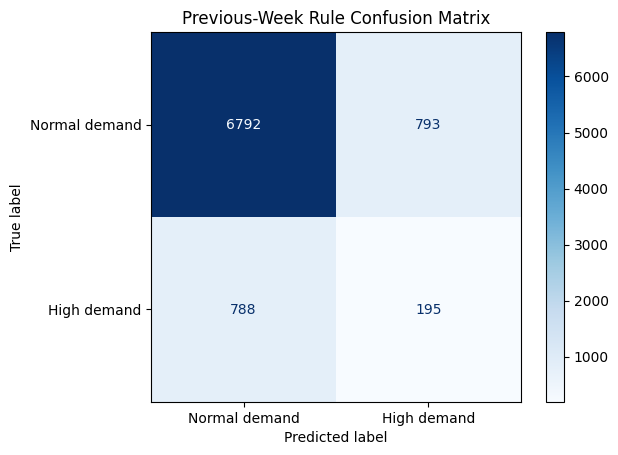

In [15]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

rule_matrix = confusion_matrix(
    y_true_rule,
    y_pred_rule
)

ConfusionMatrixDisplay(
    confusion_matrix=rule_matrix,
    display_labels=[
        "Normal demand",
        "High demand"
    ]
).plot(cmap="Blues")

plt.title("Previous-Week Rule Confusion Matrix")
plt.show()

In [16]:
model_df = df.copy()

model_df["hour"] = model_df["datetime"].dt.hour
model_df["day_of_week"] = model_df["datetime"].dt.dayofweek
model_df["month"] = model_df["datetime"].dt.month

model_df["is_weekend"] = (
    model_df["day_of_week"] >= 5
).astype(int)

model_df.head()

,datetime,arrivals,high_demand,previous_week_target,hour,day_of_week,month,is_weekend
0,2014-01-01 00:00:00,2,0,NaN,0,2,1,0
1,2014-01-01 01:00:00,2,0,NaN,1,2,1,0
2,2014-01-01 02:00:00,3,0,NaN,2,2,1,0
3,2014-01-01 03:00:00,1,0,NaN,3,2,1,0
4,2014-01-01 04:00:00,1,0,NaN,4,2,1,0


In [17]:
model_df["lag_1"] = (
    model_df["arrivals"].shift(1)
)

model_df["lag_24"] = (
    model_df["arrivals"].shift(24)
)

model_df["lag_168"] = (
    model_df["arrivals"].shift(168)
)

model_df[
    [
        "datetime",
        "arrivals",
        "lag_1",
        "lag_24",
        "lag_168"
    ]
].head(170)

,datetime,arrivals,lag_1,lag_24,lag_168
0,2014-01-01 00:00:00,2,NaN,NaN,NaN
1,2014-01-01 01:00:00,2,2.0,NaN,NaN
2,2014-01-01 02:00:00,3,2.0,NaN,NaN
3,2014-01-01 03:00:00,1,3.0,NaN,NaN
4,2014-01-01 04:00:00,1,1.0,NaN,NaN
...,...,...,...,...,...
165,2014-01-07 21:00:00,3,1.0,3.0,NaN
166,2014-01-07 22:00:00,4,3.0,5.0,NaN
167,2014-01-07 23:00:00,3,4.0,1.0,NaN
168,2014-01-08 00:00:00,4,3.0,1.0,2.0


In [18]:
model_df["rolling_mean_3"] = (
    model_df["arrivals"]
    .shift(1)
    .rolling(3)
    .mean()
)

model_df["rolling_mean_6"] = (
    model_df["arrivals"]
    .shift(1)
    .rolling(6)
    .mean()
)

model_df["rolling_mean_24"] = (
    model_df["arrivals"]
    .shift(1)
    .rolling(24)
    .mean()
)

model_df[
    [
        "datetime",
        "arrivals",
        "rolling_mean_3",
        "rolling_mean_6",
        "rolling_mean_24"
    ]
].head(30)

,datetime,arrivals,rolling_mean_3,rolling_mean_6,rolling_mean_24
0,2014-01-01 00:00:00,2,NaN,NaN,NaN
1,2014-01-01 01:00:00,2,NaN,NaN,NaN
2,2014-01-01 02:00:00,3,NaN,NaN,NaN
3,2014-01-01 03:00:00,1,2.333333,NaN,NaN
4,2014-01-01 04:00:00,1,2.000000,NaN,NaN
5,2014-01-01 05:00:00,2,1.666667,NaN,NaN
6,2014-01-01 06:00:00,2,1.333333,1.833333,NaN
7,2014-01-01 07:00:00,5,1.666667,1.833333,NaN
8,2014-01-01 08:00:00,5,3.000000,2.333333,NaN
9,2014-01-01 09:00:00,6,4.000000,2.666667,NaN


In [19]:
model_df = model_df.dropna().reset_index(drop=True)

print("Rows after removing incomplete rows:", len(model_df))

Rows after removing incomplete rows: 34104


In [20]:
features = [
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_3",
    "rolling_mean_6",
    "rolling_mean_24"
]

X = model_df[features]
y = model_df["high_demand"]

print("Number of features:", len(features))
print(features)

Number of features: 10
['hour', 'day_of_week', 'month', 'is_weekend', 'lag_1', 'lag_24', 'lag_168', 'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_24']


In [21]:
train_model = model_df[
    model_df["datetime"] < split_date
].copy()

test_model = model_df[
    model_df["datetime"] >= split_date
].copy()

X_train = train_model[features]
y_train = train_model["high_demand"]

X_test = test_model[features]
y_test = test_model["high_demand"]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (25536, 10)
Testing features: (8568, 10)


In [22]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = (
    negative_count / positive_count
)

print("Normal-demand training rows:", negative_count)
print("High-demand training rows:", positive_count)
print("Class weight:", scale_pos_weight)

Normal-demand training rows: 24110
High-demand training rows: 1426
Class weight: 16.90743338008415


In [23]:
%pip install -q xgboost

from xgboost import XGBClassifier

In [24]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train, y_train)

print("XGBoost model training completed.")

XGBoost model training completed.


In [25]:
xgb_probability = (
    xgb_model.predict_proba(X_test)[:, 1]
)

xgb_prediction = (
    xgb_probability >= 0.50
).astype(int)

print("Predictions created.")

Predictions created.


In [26]:
xgb_recall = recall_score(
    y_test,
    xgb_prediction,
    zero_division=0
)

xgb_precision = precision_score(
    y_test,
    xgb_prediction,
    zero_division=0
)

xgb_f1 = f1_score(
    y_test,
    xgb_prediction,
    zero_division=0
)

xgb_pr_auc = average_precision_score(
    y_test,
    xgb_probability
)

print("XGBoost results")
print("Recall:", xgb_recall)
print("Precision:", xgb_precision)
print("F1-score:", xgb_f1)
print("PR-AUC:", xgb_pr_auc)

XGBoost results
Recall: 0.8484231943031536
Precision: 0.2062314540059347
F1-score: 0.331808235528148
PR-AUC: 0.21947196767092467


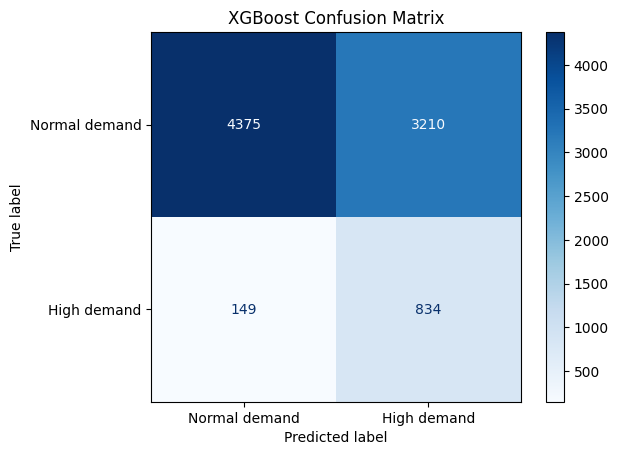

In [27]:
xgb_matrix = confusion_matrix(
    y_test,
    xgb_prediction
)

ConfusionMatrixDisplay(
    confusion_matrix=xgb_matrix,
    display_labels=[
        "Normal demand",
        "High demand"
    ]
).plot(cmap="Blues")

plt.title("XGBoost Confusion Matrix")
plt.show()

In [28]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": xgb_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

importance

,Feature,Importance
0,hour,0.602909
9,rolling_mean_24,0.067759
2,month,0.056717
7,rolling_mean_3,0.053019
6,lag_168,0.048310
1,day_of_week,0.047978
4,lag_1,0.043357
8,rolling_mean_6,0.040715
5,lag_24,0.039236
3,is_weekend,0.000000


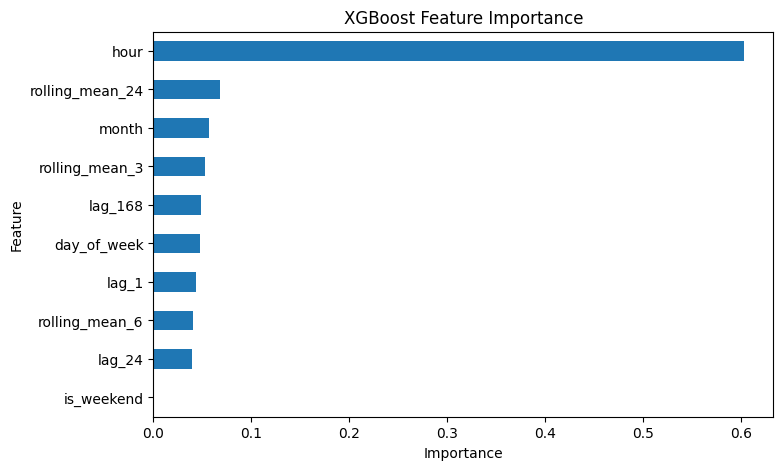

In [29]:
importance.sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(8, 5),
    legend=False
)

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.show()

In [30]:
comparison = pd.DataFrame({
    "Model": [
        "Previous-week rule",
        "XGBoost"
    ],
    "Recall": [
        rule_recall,
        xgb_recall
    ],
    "Precision": [
        rule_precision,
        xgb_precision
    ],
    "F1-score": [
        rule_f1,
        xgb_f1
    ],
    "PR-AUC": [
        rule_pr_auc,
        xgb_pr_auc
    ]
})

comparison

,Model,Recall,Precision,F1-score,PR-AUC
0,Previous-week rule,0.198372,0.197368,0.197869,0.131123
1,XGBoost,0.848423,0.206231,0.331808,0.219472


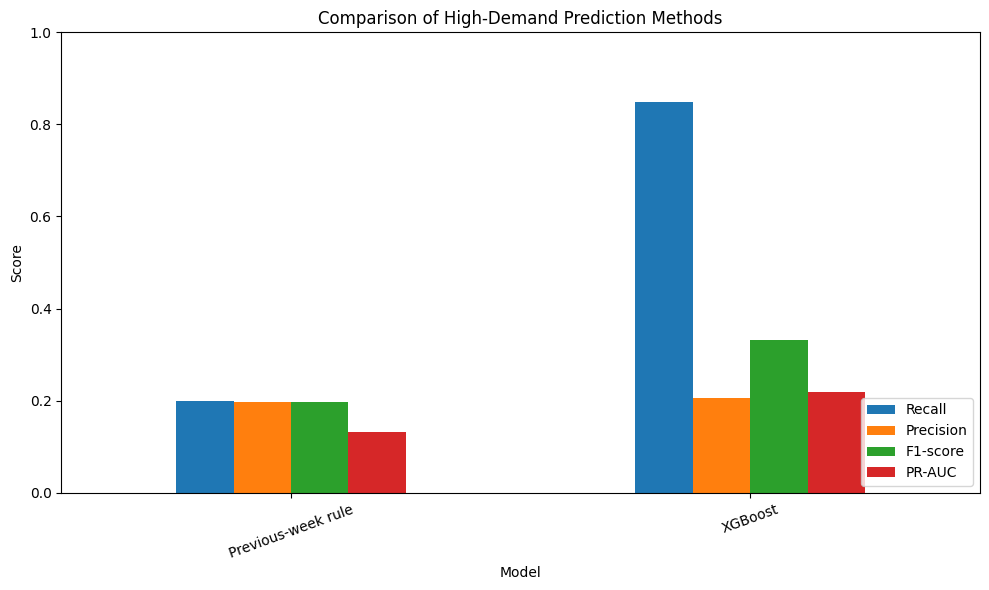

In [31]:
comparison.set_index("Model")[
    ["Recall", "Precision", "F1-score", "PR-AUC"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of High-Demand Prediction Methods")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Results Summary

The 90th-percentile threshold was 8 arrivals. Using this threshold, 5.57% of the training hours were classified as high-demand hours.

The previous-week rule produced a recall of 0.198, precision of 0.197, F1-score of 0.198, and PR-AUC of 0.131.

The XGBoost model produced a recall of 0.848, precision of 0.206, F1-score of 0.332, and PR-AUC of 0.219. XGBoost detected more high-demand hours than the simple rule, but it also produced many false alarms.

The hour of day was the most important XGBoost feature, followed by the 24-hour rolling average and month. These results suggest that emergency-department demand changes strongly according to time of day and recent arrival patterns.

ARIMA results will be added after the teammate provides the ARIMA forecast evaluation.

## Time-Based Train/Test Split Validation

This section validates the chronological train/test split, threshold calculation, class distribution, and time coverage. It also checks for missing calendar dates and fully blank source-data days.

In [32]:
# Chronological split validation

split_summary = pd.DataFrame({
    "Dataset": ["Full dataset", "Training set", "Testing set"],
    "Start date": [
        df["datetime"].min(),
        train_df["datetime"].min(),
        test_df["datetime"].min()
    ],
    "End date": [
        df["datetime"].max(),
        train_df["datetime"].max(),
        test_df["datetime"].max()
    ],
    "Rows": [
        len(df),
        len(train_df),
        len(test_df)
    ]
})

display(split_summary)

# Validation checks
assert df["datetime"].is_monotonic_increasing, \
    "The dataset is not sorted chronologically."

assert train_df["datetime"].max() < test_df["datetime"].min(), \
    "The training and testing periods overlap."

assert set(train_df.index).isdisjoint(set(test_df.index)), \
    "Some observations appear in both sets."

assert len(train_df) + len(test_df) == len(df), \
    "Some observations were lost or duplicated."

print("Chronological split validation: PASSED")
print("Random shuffling used: No")
print("Train/test overlap: No")

# Model-ready rows after lag and rolling features
print("\nModel-ready training rows:", len(train_model))
print("Model-ready testing rows:", len(test_model))

,Dataset,Start date,End date,Rows
0,Full dataset,2014-01-01,2017-12-30 23:00:00,34272
1,Training set,2014-01-01,2016-12-30 23:00:00,25704
2,Testing set,2017-01-01,2017-12-30 23:00:00,8568


Chronological split validation: PASSED
Random shuffling used: No
Train/test overlap: No

Model-ready training rows: 25536
Model-ready testing rows: 8568


In [33]:
# Validate that the threshold was calculated from training data only

recalculated_threshold = (
    train_df["arrivals"].quantile(0.90)
)

print("Stored threshold:", threshold_90)
print("Recalculated training-only threshold:",
      recalculated_threshold)

assert np.isclose(
    threshold_90,
    recalculated_threshold
), "The threshold was not calculated correctly."

print("Training-only threshold validation: PASSED")


def class_balance_summary(data, dataset_name):
    counts = (
        data["high_demand"]
        .value_counts()
        .reindex([0, 1], fill_value=0)
    )

    percentages = (
        counts / counts.sum() * 100
    )

    return pd.DataFrame({
        "Dataset": dataset_name,
        "Class": [
            "Normal demand",
            "High demand"
        ],
        "Count": counts.values,
        "Percentage": percentages.values
    })


train_labeled = df[
    df["datetime"] < split_date
].copy()

test_labeled = df[
    df["datetime"] >= split_date
].copy()

balance_summary = pd.concat([
    class_balance_summary(
        train_labeled,
        "Training"
    ),
    class_balance_summary(
        test_labeled,
        "Testing"
    )
], ignore_index=True)

display(balance_summary)

Stored threshold: 8.0
Recalculated training-only threshold: 8.0
Training-only threshold validation: PASSED


,Dataset,Class,Count,Percentage
0,Training,Normal demand,24273,94.432773
1,Training,High demand,1431,5.567227
2,Testing,Normal demand,7585,88.527077
3,Testing,High demand,983,11.472923


In [34]:
# Check whether consecutive rows are exactly one hour apart

time_differences = (
    df["datetime"].diff().dropna()
)

irregular_gaps = time_differences[
    time_differences != pd.Timedelta(hours=1)
]

print("Number of non-hourly gaps:",
      len(irregular_gaps))

if len(irregular_gaps) > 0:
    print("Largest time gap:",
          irregular_gaps.max())

    gap_locations = df.loc[
        irregular_gaps.index,
        ["datetime"]
    ].copy()

    gap_locations["Previous datetime"] = (
        df.loc[
            irregular_gaps.index - 1,
            "datetime"
        ].values
    )

    gap_locations["Gap length"] = (
        irregular_gaps.values
    )

    display(gap_locations.head(20))
else:
    print("The hourly timeline is continuous.")

Number of non-hourly gaps: 32
Largest time gap: 1 days 01:00:00


,datetime,Previous datetime,Gap length
720,2014-02-01,2014-01-30 23:00:00,1 days 01:00:00
2112,2014-04-01,2014-03-30 23:00:00,1 days 01:00:00
3552,2014-06-01,2014-05-30 23:00:00,1 days 01:00:00
4248,2014-07-01,2014-06-29 23:00:00,1 days 01:00:00
4968,2014-08-01,2014-07-30 23:00:00,1 days 01:00:00
6408,2014-10-01,2014-09-29 23:00:00,1 days 01:00:00
7128,2014-11-01,2014-10-30 23:00:00,1 days 01:00:00
8568,2015-01-01,2014-12-30 23:00:00,1 days 01:00:00
9288,2015-02-01,2015-01-30 23:00:00,1 days 01:00:00
10680,2015-04-01,2015-03-30 23:00:00,1 days 01:00:00


In [35]:
import re
import calendar
from datetime import datetime

# Identify recurring month/day labels absent from the source header

retained_dates = set()

for _, label in date_columns:
    match = re.fullmatch(
        r"(\d{1,2})-([A-Za-z]{3})",
        str(label).strip()
    )

    if match:
        day = int(match.group(1))
        month = datetime.strptime(
            match.group(2),
            "%b"
        ).month

        retained_dates.add((month, day))


# Leap year 2000 includes all 366 possible month/day combinations
expected_dates = {
    (date.month, date.day)
    for date in pd.date_range(
        "2000-01-01",
        "2000-12-31",
        freq="D"
    )
}

missing_date_labels = sorted(
    expected_dates - retained_dates
)

missing_label_table = pd.DataFrame([
    {
        "Missing source label":
            f"{calendar.month_abbr[month]} {day}"
    }
    for month, day in missing_date_labels
])

print("Retained month/day labels:",
      len(retained_dates))

print("Missing possible month/day labels:",
      len(missing_date_labels))

display(missing_label_table)

Retained month/day labels: 357
Missing possible month/day labels: 9


,Missing source label
0,Jan 31
1,Feb 29
2,Mar 31
3,May 31
4,Jun 30
5,Jul 31
6,Sep 30
7,Oct 31
8,Dec 31


In [36]:
# Identify dates for which the daily total and all 24 hourly cells are blank

year_total_rows = {}

for row in range(6, raw.shape[0]):
    label = str(raw.iloc[row, 0]).strip()

    if label.isdigit():
        year = int(label)

        if 1900 <= year <= 2100:
            year_total_rows[year] = row


blank_days = []

for year, total_row in year_total_rows.items():

    hour_rows = [
        item["row"]
        for item in row_info
        if item["year"] == year
    ]

    for col, date_label in date_columns:

        daily_total = pd.to_numeric(
            raw.iloc[total_row, col],
            errors="coerce"
        )

        hourly_values = pd.to_numeric(
            raw.iloc[hour_rows, col],
            errors="coerce"
        )

        if (
            pd.isna(daily_total)
            and hourly_values.isna().all()
        ):
            date = pd.to_datetime(
                f"{year}-{date_label}",
                format="%Y-%d-%b"
            )

            blank_days.append({
                "Date": date,
                "Year": year,
                "Source status":
                    "Daily total and all 24 hours blank",
                "Current preprocessing":
                    "Converted to 0"
            })


blank_days_table = pd.DataFrame(blank_days)

print("Fully blank dates found:",
      len(blank_days_table))

display(blank_days_table)

Fully blank dates found: 12


,Date,Year,Source status,Current preprocessing
0,2014-02-28,2014,Daily total and all 24 hours blank,Converted to 0
1,2014-04-30,2014,Daily total and all 24 hours blank,Converted to 0
2,2015-02-28,2015,Daily total and all 24 hours blank,Converted to 0
3,2015-08-31,2015,Daily total and all 24 hours blank,Converted to 0
4,2015-11-30,2015,Daily total and all 24 hours blank,Converted to 0
5,2016-04-30,2016,Daily total and all 24 hours blank,Converted to 0
6,2016-08-31,2016,Daily total and all 24 hours blank,Converted to 0
7,2016-11-30,2016,Daily total and all 24 hours blank,Converted to 0
8,2017-02-28,2017,Daily total and all 24 hours blank,Converted to 0
9,2017-04-30,2017,Daily total and all 24 hours blank,Converted to 0


### Validation Summary

The dataset was divided chronologically at January 1, 2017. No random shuffling was used, and the training and testing periods do not overlap. The high-demand threshold was calculated using the training period only.

The training period contains 25,704 rows, while the testing period contains 8,568 rows. The high-demand rate increased from 5.57% in training to 11.47% in testing, indicating a change in class distribution.

The source spreadsheet contains 357 recurring month/day labels. Nine possible calendar labels are absent from the source header. In addition, 12 dates have blank daily totals and blank values for all 24 hours. The current preprocessing converts these fully blank dates to zero-arrival days. The team will determine whether to exclude these dates as missing observations or retain and document the current assumption.

In [37]:
## Missing-Data and Feature Engineering Validation

In [38]:
records_corrected = []

In [39]:
for item in row_info:

    row = item["row"]
    year = item["year"]
    hour = item["hour"]

    for col, date_label in date_columns:

        arrivals = pd.to_numeric(
            raw.iloc[row, col],
            errors="coerce"
        )

        timestamp = pd.to_datetime(
            f"{year}-{date_label}",
            format="%Y-%d-%b"
        ) + pd.Timedelta(hours=hour)

        records_corrected.append({
            "datetime": timestamp,
            "arrivals": arrivals
        })

In [40]:
df_corrected = pd.DataFrame(records_corrected)

df_corrected = (
    df_corrected
    .sort_values("datetime")
    .reset_index(drop=True)
)

df_corrected.head()

,datetime,arrivals
0,2014-01-01 00:00:00,2.0
1,2014-01-01 01:00:00,2.0
2,2014-01-01 02:00:00,3.0
3,2014-01-01 03:00:00,1.0
4,2014-01-01 04:00:00,1.0


In [41]:
print("Total rows:", len(df_corrected))
print("Missing arrival values:", df_corrected["arrivals"].isna().sum())

Total rows: 34272
Missing arrival values: 2299


In [42]:
df_corrected[df_corrected["arrivals"].isna()].head(30)

,datetime,arrivals
29,2014-01-02 05:00:00,NaN
47,2014-01-02 23:00:00,NaN
50,2014-01-03 02:00:00,NaN
51,2014-01-03 03:00:00,NaN
53,2014-01-03 05:00:00,NaN
56,2014-01-03 08:00:00,NaN
103,2014-01-05 07:00:00,NaN
119,2014-01-05 23:00:00,NaN
122,2014-01-06 02:00:00,NaN
149,2014-01-07 05:00:00,NaN


In [43]:
missing_by_date = (
    df_corrected
    .assign(date=df_corrected["datetime"].dt.date)
    .groupby("date")["arrivals"]
    .agg(
        total_hours="size",
        missing_hours=lambda x: x.isna().sum()
    )
)

missing_by_date = missing_by_date[
    missing_by_date["missing_hours"] > 0
]

missing_by_date.head(30)

,total_hours,missing_hours
date,,
2014-01-02,24,2
2014-01-03,24,4
2014-01-05,24,2
2014-01-06,24,1
2014-01-07,24,1
2014-01-08,24,1
2014-01-09,24,2
2014-01-10,24,1
2014-01-11,24,2


In [44]:
fully_missing_days = missing_by_date[
    missing_by_date["missing_hours"] == 24
]

print("Fully missing days:", len(fully_missing_days))
fully_missing_days

Fully missing days: 12


,total_hours,missing_hours
date,,
2014-02-28,24,24
2014-04-30,24,24
2015-02-28,24,24
2015-08-31,24,24
2015-11-30,24,24
2016-04-30,24,24
2016-08-31,24,24
2016-11-30,24,24
2017-02-28,24,24


In [45]:
partially_missing_days = missing_by_date[
    (missing_by_date["missing_hours"] > 0) &
    (missing_by_date["missing_hours"] < 24)
]

print("Partially missing days:", len(partially_missing_days))
partially_missing_days.head(30)

Partially missing days: 1071


,total_hours,missing_hours
date,,
2014-01-02,24,2
2014-01-03,24,4
2014-01-05,24,2
2014-01-06,24,1
2014-01-07,24,1
2014-01-08,24,1
2014-01-09,24,2
2014-01-10,24,1
2014-01-11,24,2


In [46]:
expected_hours = pd.date_range(
    start=df_corrected["datetime"].min(),
    end=df_corrected["datetime"].max(),
    freq="h"
)

missing_timestamps = expected_hours.difference(
    df_corrected["datetime"]
)

print("Completely absent hourly timestamps:", len(missing_timestamps))
missing_timestamps[:50]

Completely absent hourly timestamps: 768


DatetimeIndex(['2014-01-31 00:00:00', '2014-01-31 01:00:00',
               '2014-01-31 02:00:00', '2014-01-31 03:00:00',
               '2014-01-31 04:00:00', '2014-01-31 05:00:00',
               '2014-01-31 06:00:00', '2014-01-31 07:00:00',
               '2014-01-31 08:00:00', '2014-01-31 09:00:00',
               '2014-01-31 10:00:00', '2014-01-31 11:00:00',
               '2014-01-31 12:00:00', '2014-01-31 13:00:00',
               '2014-01-31 14:00:00', '2014-01-31 15:00:00',
               '2014-01-31 16:00:00', '2014-01-31 17:00:00',
               '2014-01-31 18:00:00', '2014-01-31 19:00:00',
               '2014-01-31 20:00:00', '2014-01-31 21:00:00',
               '2014-01-31 22:00:00', '2014-01-31 23:00:00',
               '2014-03-31 00:00:00', '2014-03-31 01:00:00',
               '2014-03-31 02:00:00', '2014-03-31 03:00:00',
               '2014-03-31 04:00:00', '2014-03-31 05:00:00',
               '2014-03-31 06:00:00', '2014-03-31 07:00:00',
               '2014-03-

In [47]:
missing_dates = pd.Series(
    missing_timestamps.date
).drop_duplicates()

print("Completely absent calendar dates:", len(missing_dates))
missing_dates

Completely absent calendar dates: 32


,0
0,2014-01-31
24,2014-03-31
48,2014-05-31
72,2014-06-30
96,2014-07-31
120,2014-09-30
144,2014-10-31
168,2014-12-31
192,2015-01-31
216,2015-03-31


In [48]:
print("Completely absent calendar dates:")
for d in missing_dates:
    print(d)

Completely absent calendar dates:
2014-01-31
2014-03-31
2014-05-31
2014-06-30
2014-07-31
2014-09-30
2014-10-31
2014-12-31
2015-01-31
2015-03-31
2015-05-31
2015-06-30
2015-07-31
2015-09-30
2015-10-31
2015-12-31
2016-01-31
2016-02-29
2016-03-31
2016-05-31
2016-06-30
2016-07-31
2016-09-30
2016-10-31
2016-12-31
2017-01-31
2017-03-31
2017-05-31
2017-06-30
2017-07-31
2017-09-30
2017-10-31


In [49]:
missing_distribution = (
    partially_missing_days["missing_hours"]
    .value_counts()
    .sort_index()
)

print("Number of partially missing days by missing-hour count:")
print(missing_distribution)

Number of partially missing days by missing-hour count:
missing_hours
1     500
2     360
3     141
4      58
5       5
6       2
7       1
23      4
Name: count, dtype: int64


In [50]:
missing_pct = (
    df_corrected["arrivals"].isna().mean() * 100
)

print(f"Missing hourly arrival values: {missing_pct:.2f}%")

Missing hourly arrival values: 6.71%


In [51]:
full_index = pd.date_range(
    start=df_corrected["datetime"].min(),
    end=df_corrected["datetime"].max(),
    freq="h"
)

df_hourly = (
    df_corrected
    .set_index("datetime")
    .reindex(full_index)
    .rename_axis("datetime")
    .reset_index()
)

print("Rows after creating complete hourly timeline:", len(df_hourly))
print("Missing arrival values:", df_hourly["arrivals"].isna().sum())

df_hourly.head()

Rows after creating complete hourly timeline: 35040
Missing arrival values: 3067


,datetime,arrivals
0,2014-01-01 00:00:00,2.0
1,2014-01-01 01:00:00,2.0
2,2014-01-01 02:00:00,3.0
3,2014-01-01 03:00:00,1.0
4,2014-01-01 04:00:00,1.0


### Time-Based Features
Create calendar features that may capture hourly, weekly, and seasonal patterns in emergency-department demand.

In [52]:
df_hourly["hour"] = df_hourly["datetime"].dt.hour
df_hourly["day_of_week"] = df_hourly["datetime"].dt.dayofweek
df_hourly["month"] = df_hourly["datetime"].dt.month

df_hourly["is_weekend"] = (
    df_hourly["day_of_week"] >= 5
).astype(int)

df_hourly[
    ["datetime", "arrivals", "hour", "day_of_week", "month", "is_weekend"]
].head()

,datetime,arrivals,hour,day_of_week,month,is_weekend
0,2014-01-01 00:00:00,2.0,0,2,1,0
1,2014-01-01 01:00:00,2.0,1,2,1,0
2,2014-01-01 02:00:00,3.0,2,2,1,0
3,2014-01-01 03:00:00,1.0,3,2,1,0
4,2014-01-01 04:00:00,1.0,4,2,1,0


### Lag Features
Lag features use past emergency-department arrivals to help predict future demand.

In [53]:
df_hourly["lag_1"] = df_hourly["arrivals"].shift(1)
df_hourly["lag_24"] = df_hourly["arrivals"].shift(24)
df_hourly["lag_168"] = df_hourly["arrivals"].shift(168)

df_hourly[
    ["datetime", "arrivals", "lag_1", "lag_24", "lag_168"]
].head(175)

,datetime,arrivals,lag_1,lag_24,lag_168
0,2014-01-01 00:00:00,2.0,NaN,NaN,NaN
1,2014-01-01 01:00:00,2.0,2.0,NaN,NaN
2,2014-01-01 02:00:00,3.0,2.0,NaN,NaN
3,2014-01-01 03:00:00,1.0,3.0,NaN,NaN
4,2014-01-01 04:00:00,1.0,1.0,NaN,NaN
...,...,...,...,...,...
170,2014-01-08 02:00:00,1.0,1.0,2.0,3.0
171,2014-01-08 03:00:00,NaN,1.0,1.0,1.0
172,2014-01-08 04:00:00,1.0,NaN,1.0,1.0
173,2014-01-08 05:00:00,3.0,1.0,NaN,2.0


### Rolling-Average Features
Rolling averages summarize recent demand while using only previous observations to avoid data leakage.

In [54]:
df_hourly["rolling_mean_3"] = (
    df_hourly["arrivals"]
    .shift(1)
    .rolling(3, min_periods=3)
    .mean()
)

df_hourly["rolling_mean_6"] = (
    df_hourly["arrivals"]
    .shift(1)
    .rolling(6, min_periods=6)
    .mean()
)

df_hourly["rolling_mean_24"] = (
    df_hourly["arrivals"]
    .shift(1)
    .rolling(24, min_periods=24)
    .mean()
)

df_hourly[
    [
        "datetime",
        "arrivals",
        "rolling_mean_3",
        "rolling_mean_6",
        "rolling_mean_24"
    ]
].head(30)

,datetime,arrivals,rolling_mean_3,rolling_mean_6,rolling_mean_24
0,2014-01-01 00:00:00,2.0,NaN,NaN,NaN
1,2014-01-01 01:00:00,2.0,NaN,NaN,NaN
2,2014-01-01 02:00:00,3.0,NaN,NaN,NaN
3,2014-01-01 03:00:00,1.0,2.333333,NaN,NaN
4,2014-01-01 04:00:00,1.0,2.000000,NaN,NaN
5,2014-01-01 05:00:00,2.0,1.666667,NaN,NaN
6,2014-01-01 06:00:00,2.0,1.333333,1.833333,NaN
7,2014-01-01 07:00:00,5.0,1.666667,1.833333,NaN
8,2014-01-01 08:00:00,5.0,3.000000,2.333333,NaN
9,2014-01-01 09:00:00,6.0,4.000000,2.666667,NaN


In [55]:
feature_cols = [
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_3",
    "rolling_mean_6",
    "rolling_mean_24"
]

required_cols = ["arrivals"] + feature_cols

print("Total rows:", len(df_hourly))

print(
    "Rows with complete arrivals + features:",
    df_hourly[required_cols].notna().all(axis=1).sum()
)

print(
    "Rows excluded because something is missing:",
    (~df_hourly[required_cols].notna().all(axis=1)).sum()
)

Total rows: 35040
Rows with complete arrivals + features: 6928
Rows excluded because something is missing: 28112


In [56]:
model_df_corrected = (
    df_hourly
    .dropna(subset=required_cols)
    .copy()
)

print("Final usable rows:", len(model_df_corrected))

model_df_corrected[
    ["datetime", "arrivals"] + feature_cols
].head()

Final usable rows: 6928


,datetime,arrivals,hour,day_of_week,month,is_weekend,lag_1,lag_24,lag_168,rolling_mean_3,rolling_mean_6,rolling_mean_24
196,2014-01-09 04:00:00,1.0,4,3,1,0,1.0,1.0,1.0,2.000000,1.666667,3.166667
267,2014-01-12 03:00:00,2.0,3,6,1,1,1.0,4.0,1.0,3.333333,4.000000,4.708333
630,2014-01-27 06:00:00,3.0,6,0,1,0,2.0,1.0,2.0,1.333333,1.333333,4.000000
631,2014-01-27 07:00:00,3.0,7,0,1,0,3.0,3.0,5.0,2.000000,1.666667,4.083333
632,2014-01-27 08:00:00,4.0,8,0,1,0,3.0,2.0,2.0,2.666667,1.833333,4.083333


In [57]:
model_df_corrected = (
    df_hourly
    .dropna(subset=["arrivals"])
    .copy()
)

print("Total complete timeline rows:", len(df_hourly))
print("Rows with known arrivals:", len(model_df_corrected))
print(
    "Rows removed because current arrivals are unknown:",
    df_hourly["arrivals"].isna().sum()
)

Total complete timeline rows: 35040
Rows with known arrivals: 31973
Rows removed because current arrivals are unknown: 3067


In [58]:
feature_missing = (
    model_df_corrected[feature_cols]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

feature_missing

,0
rolling_mean_24,24485
rolling_mean_6,7962
rolling_mean_3,4433
lag_168,2818
lag_24,2632
lag_1,1663
day_of_week,0
hour,0
month,0
is_weekend,0


In [59]:
feature_missing_pct = (
    model_df_corrected[feature_cols]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(feature_missing_pct.round(2))

rolling_mean_24    76.58
rolling_mean_6     24.90
rolling_mean_3     13.86
lag_168             8.81
lag_24              8.23
lag_1               5.20
day_of_week         0.00
hour                0.00
month               0.00
is_weekend          0.00
dtype: float64


In [60]:
feature_cols_final = [
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_3",
    "rolling_mean_6"
]

print(feature_cols_final)

['hour', 'day_of_week', 'month', 'is_weekend', 'lag_1', 'lag_24', 'lag_168', 'rolling_mean_3', 'rolling_mean_6']


In [61]:
train_df = model_df_corrected[
    model_df_corrected["datetime"] < "2017-01-01"
].copy()

test_df = model_df_corrected[
    model_df_corrected["datetime"] >= "2017-01-01"
].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("Training period:",
      train_df["datetime"].min(),
      "to",
      train_df["datetime"].max())

print("Testing period:",
      test_df["datetime"].min(),
      "to",
      test_df["datetime"].max())

Training rows: 23840
Testing rows: 8133
Training period: 2014-01-01 00:00:00 to 2016-12-30 23:00:00
Testing period: 2017-01-01 00:00:00 to 2017-12-30 23:00:00


In [62]:
threshold_90_corrected = train_df["arrivals"].quantile(0.90)

print("90th-percentile high-demand threshold:",
      threshold_90_corrected)

90th-percentile high-demand threshold: 8.0


In [63]:
train_df["high_demand"] = (
    train_df["arrivals"] > threshold_90_corrected
).astype(int)

test_df["high_demand"] = (
    test_df["arrivals"] > threshold_90_corrected
).astype(int)

In [64]:
print("Training class balance:")
print(train_df["high_demand"].value_counts())
print(train_df["high_demand"].value_counts(normalize=True).mul(100).round(2))

print("\nTesting class balance:")
print(test_df["high_demand"].value_counts())
print(test_df["high_demand"].value_counts(normalize=True).mul(100).round(2))

Training class balance:
high_demand
0    22409
1     1431
Name: count, dtype: int64
high_demand
0    94.0
1     6.0
Name: proportion, dtype: float64

Testing class balance:
high_demand
0    7150
1     983
Name: count, dtype: int64
high_demand
0    87.91
1    12.09
Name: proportion, dtype: float64


### Prepare Modeling Data and Handle Missing Predictor Values

In [65]:
X_train = train_df[feature_cols_final].copy()
X_test = test_df[feature_cols_final].copy()

y_train = train_df["high_demand"].copy()
y_test = test_df["high_demand"].copy()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (23840, 9)
X_test shape: (8133, 9)
y_train shape: (23840,)
y_test shape: (8133,)


In [66]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

In [67]:
print("Missing values in X_train after imputation:",
      X_train_imputed.isna().sum().sum())

print("Missing values in X_test after imputation:",
      X_test_imputed.isna().sum().sum())

Missing values in X_train after imputation: 0
Missing values in X_test after imputation: 0


In [68]:
imputation_values = pd.Series(
    imputer.statistics_,
    index=feature_cols_final,
    name="training_median"
)

imputation_values

,training_median
hour,12.000000
day_of_week,3.000000
month,7.000000
is_weekend,0.000000
lag_1,4.000000
lag_24,4.000000
lag_168,4.000000
rolling_mean_3,4.666667
rolling_mean_6,4.666667


### Corrected XGBoost Model

This section re-evaluates XGBoost using the corrected preprocessing pipeline. Missing arrival observations are preserved rather than converted to zero, the hourly timeline is reconstructed before generating lag features, and the 24-hour rolling-average feature is excluded because of excessive missingness.

In [69]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight_corrected = negative_count / positive_count

print("Normal-demand training rows:", negative_count)
print("High-demand training rows:", positive_count)
print(
    "scale_pos_weight:",
    round(scale_pos_weight_corrected, 3)
)

Normal-demand training rows: 22409
High-demand training rows: 1431
scale_pos_weight: 15.66


In [70]:
from xgboost import XGBClassifier

xgb_corrected = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight_corrected,
    eval_metric="logloss",
    random_state=42
)

xgb_corrected.fit(
    X_train_imputed,
    y_train
)

print("Corrected XGBoost model trained.")

Corrected XGBoost model trained.


In [71]:
xgb_prob_corrected = xgb_corrected.predict_proba(
    X_test_imputed
)[:, 1]

xgb_pred_corrected = (
    xgb_prob_corrected >= 0.50
).astype(int)

print("Predictions created.")

Predictions created.


In [72]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

precision_corrected = precision_score(
    y_test,
    xgb_pred_corrected,
    zero_division=0
)

recall_corrected = recall_score(
    y_test,
    xgb_pred_corrected,
    zero_division=0
)

f1_corrected = f1_score(
    y_test,
    xgb_pred_corrected,
    zero_division=0
)

pr_auc_corrected = average_precision_score(
    y_test,
    xgb_prob_corrected
)

print("Corrected XGBoost Results")
print("--------------------------")
print("Precision:", round(precision_corrected, 4))
print("Recall:", round(recall_corrected, 4))
print("F1-score:", round(f1_corrected, 4))
print("PR-AUC:", round(pr_auc_corrected, 4))

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        xgb_pred_corrected
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        xgb_pred_corrected
    )
)

Corrected XGBoost Results
--------------------------
Precision: 0.2096
Recall: 0.7925
F1-score: 0.3316
PR-AUC: 0.2255

Confusion Matrix:
[[4213 2937]
 [ 204  779]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.59      0.73      7150
           1       0.21      0.79      0.33       983

    accuracy                           0.61      8133
   macro avg       0.58      0.69      0.53      8133
weighted avg       0.86      0.61      0.68      8133



### Comparison with the Original XGBoost Model

The corrected preprocessing pipeline produced performance similar to the original XGBoost model. Recall decreased from 0.8484 to 0.7925, while precision increased slightly from 0.2062 to 0.2096. The F1-score remained nearly unchanged (0.3318 versus 0.3316), and PR-AUC increased from 0.2195 to 0.2255.

This suggests that preserving missing arrival observations rather than automatically replacing them with zero does not substantially reduce overall classification performance. The corrected model also avoids treating unknown emergency-department demand as genuine zero-demand hours.

### Model Comparison

This table compares the previous-week rule, the original XGBoost model, and the corrected XGBoost model. ARIMA results will be added when they are available.

In [73]:
comparison_updated = pd.DataFrame({
    "Model": [
        "Previous-week rule",
        "Original XGBoost",
        "Corrected XGBoost",
        "ARIMA"
    ],
    "Recall": [
        rule_recall,
        xgb_recall,
        recall_corrected,
        np.nan
    ],
    "Precision": [
        rule_precision,
        xgb_precision,
        precision_corrected,
        np.nan
    ],
    "F1-score": [
        rule_f1,
        xgb_f1,
        f1_corrected,
        np.nan
    ],
    "PR-AUC": [
        rule_pr_auc,
        xgb_pr_auc,
        pr_auc_corrected,
        np.nan
    ]
})

comparison_updated.round(4)

,Model,Recall,Precision,F1-score,PR-AUC
0,Previous-week rule,0.1984,0.1974,0.1979,0.1311
1,Original XGBoost,0.8484,0.2062,0.3318,0.2195
2,Corrected XGBoost,0.7925,0.2096,0.3316,0.2255
3,ARIMA,NaN,NaN,NaN,NaN


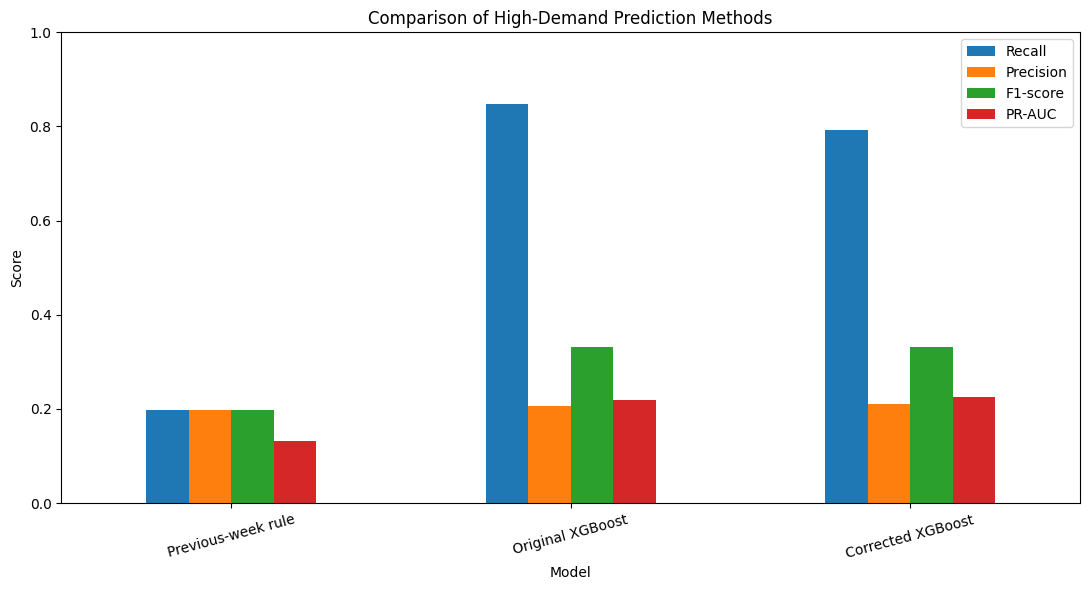

In [74]:
comparison_plot = comparison_updated.dropna()

comparison_plot.set_index("Model")[
    ["Recall", "Precision", "F1-score", "PR-AUC"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Comparison of High-Demand Prediction Methods")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

### Comparison Interpretation

The previous-week rule had substantially lower recall and F1-score than both XGBoost approaches. The original XGBoost model achieved the highest recall, detecting approximately 84.8% of high-demand hours. The corrected XGBoost model had slightly lower recall at approximately 79.3%, but slightly higher precision and PR-AUC. Its F1-score was almost identical to the original model.

Overall, the corrected preprocessing approach produced similar classification performance while avoiding the assumption that missing emergency-department arrival observations represented zero demand. ARIMA results will be incorporated into the final comparison when available.

### Corrected XGBoost Feature Importance

In [75]:
feature_importance_corrected = pd.Series(
    xgb_corrected.feature_importances_,
    index=feature_cols_final
).sort_values(ascending=False)

print(feature_importance_corrected)

hour              0.410615
lag_168           0.097396
rolling_mean_3    0.094638
lag_24            0.088363
month             0.069318
day_of_week       0.065515
lag_1             0.059496
rolling_mean_6    0.058567
is_weekend        0.056092
dtype: float32


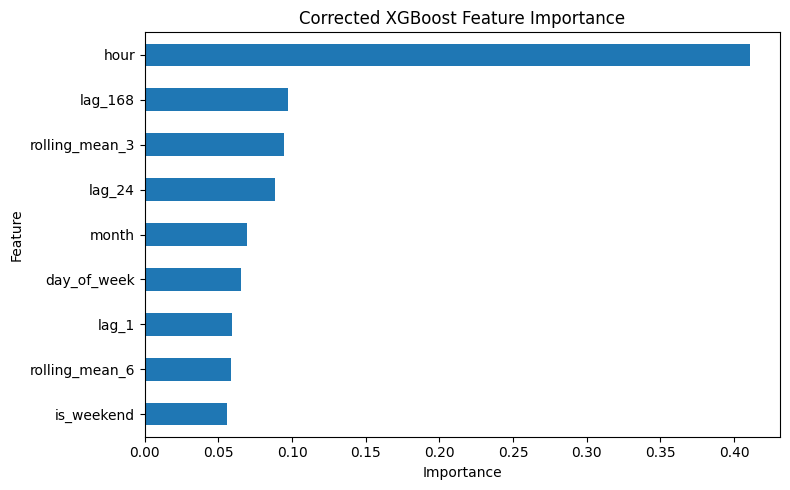

In [76]:
feature_importance_corrected.sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Corrected XGBoost Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Feature Importance Interpretation

The corrected XGBoost model identifies hour of day as the most important predictor of high emergency-department demand. This suggests that demand follows a strong within-day pattern.

The next most important predictors are the one-week lag (`lag_168`), the 3-hour rolling average, and the 24-hour lag. These results indicate that both recent demand and recurring daily/weekly patterns contribute to predicting high-demand hours.

The corrected model excludes the 24-hour rolling-average feature because it contained excessive missing values after preserving missing observations rather than replacing them with zeros.

# Shared Data Pipeline (v2)

**Purpose.** Build one clean, model-ready hourly dataset that every team member uses for baselines, models, tuning, and evaluation, so all results are computed on the same data, labels, and split.

**Decisions implemented (proposed to the team):**

| # | Decision | v2 rule |
|---|---|---|
| D1 | Blank hourly cells | Blank hour on a day that has data → **0 arrivals**. Day whose daily total *and* all 24 hours are blank → **missing (NaN)**. |
| D2 | Calendar dates absent from the source header (31st of several months, Feb 29 2016) | Rebuilt on a **complete hourly grid** and kept as **NaN**. |
| D3 | Lag / rolling features | Created **after** the grid is complete, so `lag_24` / `lag_168` are exactly 1 day / 1 week back. Rolling windows use only past hours (`shift(1)`). |
| D4 | High-demand label | `arrivals > 90th percentile` of the pre-test period (main), with `>=` and 95th-percentile versions as sensitivity checks. |
| D5 | Split | **Train** 2014–2015 · **Validation** 2016 (model / cutoff selection) · **Test** 2017 (final evaluation only). |

**Output:** `ed_hourly_clean.csv` — one row per hour, with `split`, `arrivals`, `data_status`, labels, and all features.

> This section is self-contained: it re-reads the original Excel file and does not modify any variable used by the sections above (its own variables use a `v2_` prefix where names would clash). It can be run on its own after the imports cell.

In [77]:
import os, glob, re
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.tseries.holiday import USFederalHolidayCalendar

pd.set_option("display.width", 160)

# ---------------- Configuration ----------------
DATA_GLOB  = os.environ.get("ED_DATA_GLOB", "/content/*Supplementary*")   # Colab default
OUTPUT_CSV = "ed_hourly_clean.csv"

TRAIN_END = pd.Timestamp("2016-01-01")   # train      : datetime <  2016-01-01
VAL_END   = pd.Timestamp("2017-01-01")   # validation : 2016;  test : datetime >= 2017-01-01

THRESHOLD_Q      = 0.90
THRESHOLD_PERIOD = "pre_test"   # "pre_test" = 2014–2016 (matches team's earlier threshold) | "train" = 2014–2015 only

v2_candidates = (glob.glob(DATA_GLOB) + glob.glob("*Supplementary*.xlsx")
              + glob.glob("data/*Supplementary*.xlsx"))
assert v2_candidates, "Supplementary file 1.xlsx not found — upload it or change DATA_GLOB."
v2_FILE = v2_candidates[0]
print("Data file:", v2_FILE)

Data file: /content/Supplementary+file+1.xlsx


## 1. Parse the pivot table without filling anything

The source sheet is an Excel pivot: one block per year (a year row holding **daily totals**, followed by 24 hour rows), and one column per calendar date. Blank cells are kept as NaN at this stage so we can inspect them.

In [78]:
v2_raw = pd.read_excel(v2_FILE, sheet_name=0, header=None)
print("Raw sheet shape:", v2_raw.shape)

HEADER_ROW = 2   # row holding labels such as '1-Jan', '1-Jan Total'

def parse_date_label(v):
    # Returns (month, day) for a date column, None for totals / non-date columns.
    if pd.isna(v):
        return None
    if isinstance(v, (pd.Timestamp, datetime)):
        return (v.month, v.day)
    s = str(v).strip()
    if "Total" in s:
        return None
    m = re.fullmatch(r"(\d{1,2})-([A-Za-z]{3})", s)
    if not m:
        return None
    return (datetime.strptime(m.group(2).title(), "%b").month, int(m.group(1)))

def parse_year(v):
    try:
        f = float(str(v).strip())
    except ValueError:
        return None
    return int(f) if f.is_integer() and 1900 <= f <= 2100 else None

HOUR_RE = re.compile(r"^(\d{1,2})\s*(AM|PM)$", re.IGNORECASE)

date_cols = []
for col in range(v2_raw.shape[1]):
    md_ = parse_date_label(v2_raw.iat[HEADER_ROW, col])
    if md_:
        date_cols.append((col, *md_))

year_rows, hour_rows, current_year = {}, [], None
for row in range(HEADER_ROW + 1, v2_raw.shape[0]):
    label = v2_raw.iat[row, 0]
    y = parse_year(label)
    if y is not None:
        current_year = y
        year_rows[y] = row
        continue
    m = HOUR_RE.match(str(label).strip())
    if m and current_year is not None:
        hour = datetime.strptime(f"{m.group(1)} {m.group(2).upper()}", "%I %p").hour
        hour_rows.append((row, current_year, hour))

print("Date columns :", len(date_cols))
print("Years        :", sorted(year_rows))
print("Hour rows    :", len(hour_rows))
assert len(hour_rows) == 24 * len(year_rows), "Expected 24 hour rows per year."

Raw sheet shape: (107, 718)
Date columns : 357
Years        : [2014, 2015, 2016, 2017]
Hour rows    : 96


In [79]:
v2_cols = [c for c, _, _ in date_cols]

# Hourly cells (NaN preserved)
v2_records = []
for row, year, hour in hour_rows:
    vals = pd.to_numeric(v2_raw.iloc[row, v2_cols], errors="coerce").to_numpy()
    for (col, month, day), v in zip(date_cols, vals):
        v2_records.append((year, month, day, hour, v))
long = pd.DataFrame(v2_records, columns=["year", "month", "day", "hour", "value"])

# Daily totals from each year row
tot = []
for year, row in year_rows.items():
    vals = pd.to_numeric(v2_raw.iloc[row, v2_cols], errors="coerce").to_numpy()
    for (col, month, day), v in zip(date_cols, vals):
        tot.append((year, month, day, v))
daily_total = pd.DataFrame(tot, columns=["year", "month", "day", "daily_total"])

for d in (long, daily_total):
    d["date"] = pd.to_datetime(d[["year", "month", "day"]], errors="coerce")
invalid = long["date"].isna().sum()
long = long.dropna(subset=["date"])
daily_total = daily_total.dropna(subset=["date"])
long["datetime"] = long["date"] + pd.to_timedelta(long["hour"], unit="h")
long = long.sort_values("datetime").reset_index(drop=True)

assert long["datetime"].is_unique
print("Hourly cells parsed:", len(long), "| invalid calendar cells dropped:", invalid)
print("Blank hourly cells :", long["value"].isna().sum(), f"({long['value'].isna().mean():.2%})")
print("Smallest non-blank value:", long["value"].min())

Hourly cells parsed: 34272 | invalid calendar cells dropped: 0
Blank hourly cells : 2299 (6.71%)
Smallest non-blank value: 1.0


## 2. Evidence: are blank cells zeros or missing?

Two checks:

1. **Daily total reconciliation.** For days that have a daily total, if the sum of the non-blank hours equals the daily total, then the blank hours contributed nothing to the total, i.e., they are **zero-arrival hours**, not lost records.
2. **When blanks happen.** Zero-arrival hours should concentrate in the low-volume overnight hours, and the non-blank values should never be 0 (a pivot never prints a 0 for "no rows").

In [80]:
day = (long.groupby("date")
           .agg(n_blank=("value", lambda s: s.isna().sum()),
                hourly_sum=("value", "sum"))
           .join(daily_total.set_index("date")["daily_total"]))

fully_blank = day["n_blank"].eq(24) & day["daily_total"].isna()
with_total  = day["daily_total"].notna()
partial     = with_total & day["n_blank"].gt(0)

match = np.isclose(day.loc[with_total, "hourly_sum"], day.loc[with_total, "daily_total"])
match_partial = np.isclose(day.loc[partial, "hourly_sum"], day.loc[partial, "daily_total"])

print(f"Days with a daily total                        : {with_total.sum()}")
print(f"  hourly sum == daily total                    : {match.mean():.2%}")
print(f"Days with a total AND some blank hours         : {partial.sum()}")
print(f"  hourly sum == daily total (blanks ignored)   : {match_partial.mean():.2%}")
print(f"Fully blank days (total + all 24 hours blank)  : {fully_blank.sum()}")
print(day.loc[fully_blank].index.strftime("%Y-%m-%d").tolist())

Days with a daily total                        : 1416
  hourly sum == daily total                    : 100.00%
Days with a total AND some blank hours         : 1071
  hourly sum == daily total (blanks ignored)   : 100.00%
Fully blank days (total + all 24 hours blank)  : 12
['2014-02-28', '2014-04-30', '2015-02-28', '2015-08-31', '2015-11-30', '2016-04-30', '2016-08-31', '2016-11-30', '2017-02-28', '2017-04-30', '2017-08-31', '2017-11-30']


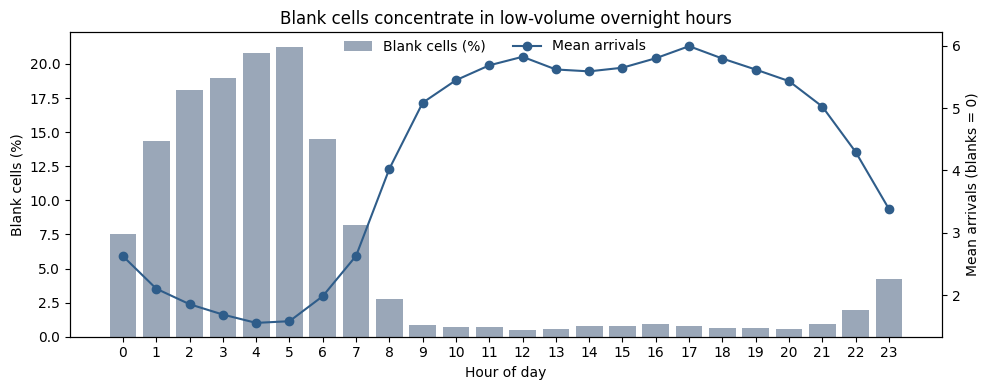

Share of all blanks (on observed days) falling in 0–6 AM: 81.4%


In [81]:
obs_days = day.index[~fully_blank]
blank_by_hour = (long[long["date"].isin(obs_days)]
                 .groupby("hour")["value"].apply(lambda s: s.isna().mean()))
mean_by_hour = long[long["date"].isin(obs_days)].groupby("hour")["value"].apply(lambda s: s.fillna(0).mean())

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(blank_by_hour.index, blank_by_hour.values * 100, color="#9aa7b8", label="Blank cells (%)")
ax1.set_xlabel("Hour of day"); ax1.set_ylabel("Blank cells (%)")
ax2 = ax1.twinx()
ax2.plot(mean_by_hour.index, mean_by_hour.values, color="#2f5d8a", marker="o", label="Mean arrivals")
ax2.set_ylabel("Mean arrivals (blanks = 0)")
ax1.set_xticks(range(24))
ax1.set_title("Blank cells concentrate in low-volume overnight hours")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.92), ncol=2, frameon=False)
plt.tight_layout(); plt.show()

print("Share of all blanks (on observed days) falling in 0–6 AM:",
      f"{long[long['date'].isin(obs_days) & long['hour'].between(0, 6)]['value'].isna().sum() / long[long['date'].isin(obs_days)]['value'].isna().sum():.1%}")

**Interpretation (fill in after running).** If the reconciliation is ~100%, the non-blank values are never 0, and blanks concentrate at night, the blanks are zero-arrival hours (D1). Only the fully blank days are treated as missing.

## 3. Apply D1 and D2: build the complete hourly series

In [82]:
long["is_fully_blank_day"] = long["date"].isin(day.index[fully_blank])
long["arrivals"] = np.where(long["is_fully_blank_day"], np.nan, long["value"].fillna(0))
long["data_status"] = np.select(
    [long["is_fully_blank_day"], long["value"].isna()],
    ["missing_day", "blank_as_zero"],
    default="observed",
)

grid = pd.date_range(long["datetime"].min().normalize(),
                     long["datetime"].max().normalize() + pd.Timedelta(hours=23), freq="h")

hourly = (long.set_index("datetime")[["arrivals", "data_status"]]
              .reindex(grid)
              .rename_axis("datetime")
              .reset_index())
hourly["data_status"] = hourly["data_status"].fillna("absent_date")

assert hourly["datetime"].is_unique and hourly["datetime"].is_monotonic_increasing
assert (hourly["datetime"].diff().dropna() == pd.Timedelta(hours=1)).all()

print("Complete hourly grid:", hourly["datetime"].min(), "→", hourly["datetime"].max(), f"({len(hourly):,} hours)")
print(hourly["data_status"].value_counts().to_string())
absent = hourly.loc[hourly["data_status"].eq("absent_date"), "datetime"].dt.normalize().unique()
print(f"\nAbsent calendar dates: {len(absent)}")

Complete hourly grid: 2014-01-01 00:00:00 → 2017-12-30 23:00:00 (35,040 hours)
data_status
observed         31973
blank_as_zero     2011
absent_date        768
missing_day        288

Absent calendar dates: 32


## 4. Features (D3)

All features describing hour *t* use only information available **before** hour *t* (lags / rolling windows on past hours) or known in advance (calendar). The target is whether hour *t* is a high-demand hour, i.e., a one-hour-ahead alert.

Rolling windows require a complete window (`min_periods = window`), so they are NaN within one window after a missing day. Tree models can use NaN directly; for LR / KNN / SVM, either drop rows with `has_all_features == 0` or impute inside the model pipeline (fit on training data only).

In [83]:
def make_features(v2_df, holidays=None):
    v2_df = v2_df.copy()
    dt, y = v2_df["datetime"], v2_df["arrivals"]

    # Calendar (known in advance)
    v2_df["hour"] = dt.dt.hour
    v2_df["day_of_week"] = dt.dt.dayofweek
    v2_df["month"] = dt.dt.month
    v2_df["is_weekend"] = (v2_df["day_of_week"] >= 5).astype(int)
    v2_df["is_holiday"] = dt.dt.normalize().isin(holidays).astype(int) if holidays is not None else 0
    for col, period in [("hour", 24), ("day_of_week", 7), ("month", 12)]:
        v2_df[f"{col}_sin"] = np.sin(2 * np.pi * v2_df[col] / period)
        v2_df[f"{col}_cos"] = np.cos(2 * np.pi * v2_df[col] / period)

    # Lags (exact offsets on the complete hourly grid)
    for k in (1, 2, 3, 24, 168):
        v2_df[f"lag_{k}"] = y.shift(k)

    # Rolling statistics on past hours only
    past = y.shift(1)
    for w in (3, 6, 24):
        v2_df[f"rolling_mean_{w}"] = past.rolling(w, min_periods=w).mean()
    v2_df["rolling_std_24"] = past.rolling(24, min_periods=24).std()
    v2_df["rolling_max_24"] = past.rolling(24, min_periods=24).max()

    # Same hour over the previous 7 days (needs at least 4 of 7 observed)
    same_hour = pd.concat([y.shift(24 * d) for d in range(1, 8)], axis=1)
    v2_df["same_hour_mean_7d"] = same_hour.mean(axis=1).where(same_hour.notna().sum(axis=1) >= 4)
    return v2_df

holidays = USFederalHolidayCalendar().holidays(start=hourly["datetime"].min(), end=hourly["datetime"].max())
hourly = make_features(hourly, holidays)

CALENDAR_FEATURES = ["hour", "day_of_week", "month", "is_weekend", "is_holiday",
                     "hour_sin", "hour_cos", "day_of_week_sin", "day_of_week_cos", "month_sin", "month_cos"]
LAG_FEATURES = ["lag_1", "lag_2", "lag_3", "lag_24", "lag_168",
                "rolling_mean_3", "rolling_mean_6", "rolling_mean_24",
                "rolling_std_24", "rolling_max_24", "same_hour_mean_7d"]
ALL_FEATURES = CALENDAR_FEATURES + LAG_FEATURES

# Leakage guards
assert hourly["lag_1"].equals(hourly["arrivals"].shift(1))
assert np.allclose(hourly["rolling_mean_3"].dropna(),
                   hourly["arrivals"].shift(1).rolling(3).mean().dropna())
print("Leakage checks passed.")

Leakage checks passed.


## 5. Split, threshold, and labels (D4, D5)

In [84]:
hourly["split"] = np.select(
    [hourly["datetime"] < TRAIN_END, hourly["datetime"] < VAL_END],
    ["train", "validation"], default="test")

def threshold_from(v2_df, period=THRESHOLD_PERIOD, q=THRESHOLD_Q):
    ref = v2_df[v2_df["split"] == "train"] if period == "train" else v2_df[v2_df["split"] != "test"]
    return ref["arrivals"].quantile(q)

THRESHOLD = threshold_from(hourly)
print(f"High-demand threshold ({THRESHOLD_PERIOD}, q={THRESHOLD_Q}): {THRESHOLD}")
print(f"(train-only alternative: {threshold_from(hourly, 'train')})")

v2_known = hourly["arrivals"].notna()
hourly["high_demand"]    = np.where(v2_known, (hourly["arrivals"] >  THRESHOLD).astype(float), np.nan)
hourly["high_demand_ge"] = np.where(v2_known, (hourly["arrivals"] >= THRESHOLD).astype(float), np.nan)
hourly["has_all_features"] = (v2_known & hourly[LAG_FEATURES].notna().all(axis=1)).astype(int)

v2_summary = (hourly[v2_known].groupby("split", sort=False)
           .agg(start=("datetime", "min"), end=("datetime", "max"),
                hours=("arrivals", "size"),
                pos_rate_gt=("high_demand", "mean"),
                pos_rate_ge=("high_demand_ge", "mean"),
                complete_feature_rows=("has_all_features", "mean")))
v2_summary[["pos_rate_gt", "pos_rate_ge", "complete_feature_rows"]] *= 100
v2_summary.round({"pos_rate_gt": 2, "pos_rate_ge": 2, "complete_feature_rows": 2})

High-demand threshold (pre_test, q=0.9): 8.0
(train-only alternative: 7.0)


,start,end,hours,pos_rate_gt,pos_rate_ge,complete_feature_rows
split,,,,,,
train,2014-01-01,2015-12-30 23:00:00,17016,4.71,8.87,93.37
validation,2016-01-01,2016-12-30 23:00:00,8496,7.40,13.15,93.22
test,2017-01-01,2017-12-30 23:00:00,8472,11.60,18.32,93.20


In [85]:
# Sensitivity: label definitions vs. positive rate in each split
v2_rows = []
for q in (0.90, 0.95):
    for period in ("pre_test", "train"):
        v2_thr = threshold_from(hourly, period, q)
        for op, fn in ((">", np.greater), (">=", np.greater_equal)):
            v2_lab = fn(hourly.loc[v2_known, "arrivals"], v2_thr)
            v2_rates = v2_lab.groupby(hourly.loc[v2_known, "split"]).mean() * 100
            v2_rows.append({"quantile": q, "threshold_period": period, "threshold": v2_thr, "rule": op,
                         **{f"pos_%_{s}": round(v2_rates.get(s, np.nan), 2) for s in ("train", "validation", "test")}})
pd.DataFrame(v2_rows)

,quantile,threshold_period,threshold,rule,pos_%_train,pos_%_validation,pos_%_test
0,0.90,pre_test,8.0,>,4.71,7.40,11.60
1,0.90,pre_test,8.0,>=,8.87,13.15,18.32
2,0.90,train,7.0,>,8.87,13.15,18.32
3,0.90,train,7.0,>=,15.13,21.75,27.23
4,0.95,pre_test,9.0,>,2.36,4.07,6.61
5,0.95,pre_test,9.0,>=,4.71,7.40,11.60
6,0.95,train,8.0,>,4.71,7.40,11.60
7,0.95,train,8.0,>=,8.87,13.15,18.32


## 6. Before / after comparison

* **v1 (original):** all blanks → 0, including fully blank days; absent dates skipped (no grid), so row shifts are not exact time offsets.
* **v1-corrected:** all blanks → NaN; complete grid.
* **v2 (this notebook):** D1–D5.

All three use the same split and the same threshold rule, so only the data handling differs.

In [86]:
def v1_original(long):
    v2_df = long[["datetime"]].copy()
    v2_df["arrivals"] = long["value"].fillna(0)
    return v2_df.sort_values("datetime").reset_index(drop=True)

def v1_corrected(long, grid):
    v2_df = long.set_index("datetime")[["value"]].rename(columns={"value": "arrivals"})
    return v2_df.reindex(grid).rename_axis("datetime").reset_index()

versions = {
    "v1 original":  v1_original(long),
    "v1 corrected": v1_corrected(long, grid),
    "v2":           hourly[["datetime", "arrivals"]].copy(),
}

v2_rows = []
for name, v2_df in versions.items():
    v2_df = make_features(v2_df, holidays)
    v2_df["split"] = np.select([v2_df["datetime"] < TRAIN_END, v2_df["datetime"] < VAL_END],
                            ["train", "validation"], default="test")
    v2_thr = threshold_from(v2_df)
    k = v2_df["arrivals"].notna()
    v2_lab = v2_df.loc[k, "arrivals"] > v2_thr
    v2_rates = v2_lab.groupby(v2_df.loc[k, "split"]).mean() * 100
    lag168_gap = v2_df["datetime"] - v2_df["datetime"].shift(168)
    v2_rows.append({
        "version": name,
        "rows": len(v2_df),
        "hours_with_arrivals": int(k.sum()),
        "zero_hours": int((v2_df["arrivals"] == 0).sum()),
        "missing_hours": int(v2_df["arrivals"].isna().sum()),
        "threshold": v2_thr,
        "pos_%_train": round(v2_rates.get("train", np.nan), 2),
        "pos_%_val": round(v2_rates.get("validation", np.nan), 2),
        "pos_%_test": round(v2_rates.get("test", np.nan), 2),
        "rolling_mean_24_NaN_%": round(v2_df.loc[k, "rolling_mean_24"].isna().mean() * 100, 2),
        "lag_168_misaligned_rows": int((lag168_gap.dropna() != pd.Timedelta(hours=168)).sum()),
    })
v2_comparison = pd.DataFrame(v2_rows).set_index("version")
v2_comparison

,rows,hours_with_arrivals,zero_hours,missing_hours,threshold,pos_%_train,pos_%_val,pos_%_test,rolling_mean_24_NaN_%,lag_168_misaligned_rows
version,,,,,,,,,,
v1 original,34272,34272,2299,0,8.0,4.68,7.34,11.47,0.07,5376
v1 corrected,35040,31973,0,3067,8.0,5.07,7.84,12.09,76.58,0
v2,35040,33984,2011,1056,8.0,4.71,7.40,11.60,3.18,0


## 7. Export

In [87]:
EXPORT_COLS = (["datetime", "split", "arrivals", "data_status",
                "high_demand", "high_demand_ge", "has_all_features"] + ALL_FEATURES)
v2_out = hourly[EXPORT_COLS].copy()
v2_out.to_csv(OUTPUT_CSV, index=False)
print(f"Saved {OUTPUT_CSV}: {v2_out.shape[0]:,} rows × {v2_out.shape[1]} columns")
print(f"Model-ready rows (target known): {int(v2_out['high_demand'].notna().sum()):,} | "
      f"with all lag features: {int(v2_out['has_all_features'].sum()):,}")

data_dictionary = pd.DataFrame([
    ("datetime", "Start of the hour"),
    ("split", "train (2014–2015) / validation (2016) / test (2017)"),
    ("arrivals", "ED arrivals in the hour; NaN = missing day or absent date"),
    ("data_status", "observed / blank_as_zero / missing_day / absent_date"),
    ("high_demand", f"1 if arrivals > {THRESHOLD} (main label); NaN if arrivals unknown"),
    ("high_demand_ge", f"1 if arrivals >= {THRESHOLD} (sensitivity label)"),
    ("has_all_features", "1 if the target and every lag/rolling feature are available"),
    ("hour … month_cos", "Calendar features incl. US federal holidays and sin/cos encodings"),
    ("lag_k", "Arrivals k hours earlier (exact time offset)"),
    ("rolling_*", "Statistics over previous hours only (window must be complete)"),
    ("same_hour_mean_7d", "Mean arrivals at the same hour over the previous 7 days (≥4 observed)"),
], columns=["column", "description"])
data_dictionary

Saved ed_hourly_clean.csv: 35,040 rows × 29 columns
Model-ready rows (target known): 33,984 | with all lag features: 31,704


,column,description
0,datetime,Start of the hour
1,split,train (2014–2015) / validation (2016) / test (...
2,arrivals,ED arrivals in the hour; NaN = missing day or ...
3,data_status,observed / blank_as_zero / missing_day / absen...
4,high_demand,1 if arrivals > 8.0 (main label); NaN if arriv...
5,high_demand_ge,1 if arrivals >= 8.0 (sensitivity label)
6,has_all_features,1 if the target and every lag/rolling feature ...
7,hour … month_cos,Calendar features incl. US federal holidays an...
8,lag_k,Arrivals k hours earlier (exact time offset)
9,rolling_*,Statistics over previous hours only (window mu...


In [88]:
# Loading snippet for teammates
v2_df = pd.read_csv(OUTPUT_CSV, parse_dates=["datetime"])
v2_model_df = v2_df[v2_df["high_demand"].notna()]
v2_train, v2_val, v2_test = (v2_model_df[v2_model_df["split"] == s] for s in ("train", "validation", "test"))
print(len(v2_train), len(v2_val), len(v2_test))

17016 8496 8472


In [89]:

c = v2_comparison
s = v2_summary
print(f'''v2 data pipeline summary
- Complete hourly grid: {len(hourly):,} hours ({hourly["datetime"].min():%Y-%m-%d} to {hourly["datetime"].max():%Y-%m-%d}).
- Daily-total reconciliation: hourly sum equals the daily total on {match.mean():.1%} of days with a total
  (blank hours ignored), so blank cells are treated as 0 arrivals.
- Missing: {int(fully_blank.sum())} fully blank days + {len(absent)} absent dates = {int(hourly["arrivals"].isna().sum()):,} hours (kept as NaN).
- Threshold: arrivals > {THRESHOLD} ({THRESHOLD_PERIOD} q{int(THRESHOLD_Q*100)}). Positive rate: train {s.loc["train","pos_rate_gt"]:.2f}% |
  validation {s.loc["validation","pos_rate_gt"]:.2f}% | test {s.loc["test","pos_rate_gt"]:.2f}%.
- rolling_mean_24 missing: {c.loc["v1 corrected","rolling_mean_24_NaN_%"]}% (v1 corrected) -> {c.loc["v2","rolling_mean_24_NaN_%"]}% (v2).
- lag_168 misaligned rows: {c.loc["v1 original","lag_168_misaligned_rows"]:,} (v1 original) -> {c.loc["v2","lag_168_misaligned_rows"]} (v2).
- File: {OUTPUT_CSV} ({v2_out.shape[1]} columns; split column included).''')

v2 data pipeline summary
- Complete hourly grid: 35,040 hours (2014-01-01 to 2017-12-30).
- Daily-total reconciliation: hourly sum equals the daily total on 100.0% of days with a total
  (blank hours ignored), so blank cells are treated as 0 arrivals.
- Missing: 12 fully blank days + 32 absent dates = 1,056 hours (kept as NaN).
- Threshold: arrivals > 8.0 (pre_test q90). Positive rate: train 4.71% |
  validation 7.40% | test 11.60%.
- rolling_mean_24 missing: 76.58% (v1 corrected) -> 3.18% (v2).
- lag_168 misaligned rows: 5,376 (v1 original) -> 0 (v2).
- File: ed_hourly_clean.csv (29 columns; split column included).


In [90]:
v2_df = pd.read_csv(
    "ed_hourly_clean.csv",
    parse_dates=["datetime"]
)

v2_df.head()

,datetime,split,arrivals,data_status,high_demand,high_demand_ge,has_all_features,hour,day_of_week,month,...,lag_2,lag_3,lag_24,lag_168,rolling_mean_3,rolling_mean_6,rolling_mean_24,rolling_std_24,rolling_max_24,same_hour_mean_7d
0,2014-01-01 00:00:00,train,2.0,observed,0.0,0.0,0,0,2,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2014-01-01 01:00:00,train,2.0,observed,0.0,0.0,0,1,2,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2014-01-01 02:00:00,train,3.0,observed,0.0,0.0,0,2,2,1,...,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2014-01-01 03:00:00,train,1.0,observed,0.0,0.0,0,3,2,1,...,2.0,2.0,NaN,NaN,2.333333,NaN,NaN,NaN,NaN,NaN
4,2014-01-01 04:00:00,train,1.0,observed,0.0,0.0,0,4,2,1,...,3.0,2.0,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,NaN


In [91]:
v2_df["rule_prediction"] = (
    v2_df["lag_168"] > 8
).astype("float")

v2_df.loc[
    v2_df["lag_168"].isna(),
    "rule_prediction"
] = np.nan

In [92]:
rule_results = []

for split_name in ["validation", "test"]:

    data = v2_df[
        (v2_df["split"] == split_name) &
        (v2_df["high_demand"].notna()) &
        (v2_df["rule_prediction"].notna())
    ]

    y_true = data["high_demand"]
    y_pred = data["rule_prediction"]

    rule_results.append({
        "Split": split_name,
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "PR-AUC": average_precision_score(y_true, y_pred)
    })

rule_results_df = pd.DataFrame(rule_results)

rule_results_df

,Split,Recall,Precision,F1-score,PR-AUC
0,validation,0.150573,0.154362,0.152444,0.086474
1,test,0.197080,0.196670,0.196875,0.132846


The previous-week rule predicts high demand when the same hour from the previous week had more than 8 arrivals. The rule is evaluated separately on the validation and test periods. The validation results can be used for comparison and cutoff decisions, while the test results are reserved for final evaluation.

## Final v2 Threshold and Class Balance

In [93]:
print("Final v2 threshold:", THRESHOLD)

v2_class_balance = (
    v2_df.groupby("split")["high_demand"]
    .mean()
    .mul(100)
    .round(2)
)

v2_class_balance

Final v2 threshold: 8.0


,high_demand
split,
test,11.60
train,4.71
validation,7.40


## Final v2 Simple Rule Baseline

In [94]:
rule_df = v2_df[
    [
        "datetime",
        "split",
        "arrivals",
        "high_demand",
        "lag_168"
    ]
].copy()

rule_df["rule_prediction"] = (
    rule_df["lag_168"] > THRESHOLD
).astype(float)

rule_df.loc[
    rule_df["lag_168"].isna(),
    "rule_prediction"
] = np.nan

In [95]:
rule_results = []

for split_name in ["validation", "test"]:

    data = rule_df[
        (rule_df["split"] == split_name) &
        (rule_df["high_demand"].notna()) &
        (rule_df["rule_prediction"].notna())
    ]

    y_true = data["high_demand"]
    y_pred = data["rule_prediction"]

    rule_results.append({
        "Split": split_name,
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "PR-AUC": average_precision_score(y_true, y_pred)
    })

v2_rule_results = pd.DataFrame(rule_results)

v2_rule_results

,Split,Recall,Precision,F1-score,PR-AUC
0,validation,0.150573,0.154362,0.152444,0.086474
1,test,0.197080,0.196670,0.196875,0.132846


**Simple Rule Baseline Results**

The previous-week rule was evaluated on the validation and test periods using the corrected v2 dataset. It achieved a recall of 0.151 on the validation set and 0.197 on the test set. On the test set, the rule achieved a precision of 0.197, an F1-score of 0.197, and a PR-AUC of 0.133. These results provide a baseline for comparing XGBoost and ARIMA.

## Time-Based Split Validation

This section independently validates the chronological train, validation, and test split in the v2 dataset. It checks the complete hourly timeline, split boundaries, row counts, missing targets, and confirms that no random shuffling or overlap was introduced.

In [96]:
# Independent validation of the v2 time-based split
import numpy as np
import pandas as pd

split_validation_df = pd.read_csv(
    "ed_hourly_clean.csv",
    parse_dates=["datetime"]
).sort_values("datetime").reset_index(drop=True)

# 1. Validate the complete hourly timeline
assert split_validation_df["datetime"].is_unique
assert split_validation_df["datetime"].is_monotonic_increasing
assert (
    split_validation_df["datetime"]
    .diff()
    .dropna()
    .eq(pd.Timedelta(hours=1))
    .all()
)

# 2. Recreate the expected chronological split
expected_split = np.select(
    [
        split_validation_df["datetime"] < pd.Timestamp("2016-01-01"),
        split_validation_df["datetime"] < pd.Timestamp("2017-01-01")
    ],
    ["train", "validation"],
    default="test"
)

assert (
    split_validation_df["split"].to_numpy()
    == expected_split
).all()

# 3. Summarize each split
split_summary = (
    split_validation_df
    .groupby("split", sort=False)
    .agg(
        grid_rows=("datetime", "size"),
        start_date=("datetime", "min"),
        end_date=("datetime", "max"),
        known_arrival_rows=("arrivals", lambda x: x.notna().sum()),
        missing_arrival_rows=("arrivals", lambda x: x.isna().sum()),
        model_ready_rows=("has_all_features", "sum")
    )
    .reindex(["train", "validation", "test"])
)

# 4. Validate expected grid row counts
expected_rows = {
    "train": 17520,
    "validation": 8784,
    "test": 8736
}

assert split_summary["grid_rows"].to_dict() == expected_rows

# 5. Confirm that the periods do not overlap
assert (
    split_validation_df.loc[
        split_validation_df["split"] == "train", "datetime"
    ].max()
    <
    split_validation_df.loc[
        split_validation_df["split"] == "validation", "datetime"
    ].min()
)

assert (
    split_validation_df.loc[
        split_validation_df["split"] == "validation", "datetime"
    ].max()
    <
    split_validation_df.loc[
        split_validation_df["split"] == "test", "datetime"
    ].min()
)

display(split_summary)

print("All v2 chronological split validation checks passed.")
print("No random shuffling was used.")
print("No overlap exists between train, validation, and test periods.")

,grid_rows,start_date,end_date,known_arrival_rows,missing_arrival_rows,model_ready_rows
split,,,,,,
train,17520,2014-01-01,2015-12-31 23:00:00,17016,504,15888
validation,8784,2016-01-01,2016-12-31 23:00:00,8496,288,7920
test,8736,2017-01-01,2017-12-30 23:00:00,8472,264,7896


All v2 chronological split validation checks passed.
No random shuffling was used.
No overlap exists between train, validation, and test periods.


### Validation Summary

The v2 dataset was successfully divided using a chronological split with no random shuffling. The training set covers 2014–2015, the validation set covers 2016, and the test set covers January 1 through December 30, 2017. The three periods do not overlap.

The complete hourly grid contains 35,040 rows. After preserving fully missing days and absent calendar dates as missing values, 33,984 rows have known arrival targets, and 31,704 rows have all required lag and rolling features. All time-based split validation checks passed.

## Feature Engineering Verification and Analysis

This section examines the time-based, lag, and rolling-average features generated by the corrected v2 data pipeline. The objective is to verify feature availability, assess missingness, and analyze their potential usefulness for predicting high emergency-department demand.

In [97]:
import pandas as pd
import numpy as np

# Load the corrected dataset generated by the v2 pipeline
df_features = pd.read_csv("ed_hourly_clean.csv")

# Display basic dataset information
print("Dataset shape:", df_features.shape)

print("\nAll columns:")
print(df_features.columns.tolist())

# Identify engineered features
feature_cols = [
    col for col in df_features.columns
    if any(keyword in col.lower()
           for keyword in ["lag", "rolling", "hour", "day", "week"])
]

print("\nTime, lag, and rolling features:")
for col in feature_cols:
    print(col)

print("\nFirst five rows:")
display(df_features.head())

Dataset shape: (35040, 29)

All columns:
['datetime', 'split', 'arrivals', 'data_status', 'high_demand', 'high_demand_ge', 'has_all_features', 'hour', 'day_of_week', 'month', 'is_weekend', 'is_holiday', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'lag_1', 'lag_2', 'lag_3', 'lag_24', 'lag_168', 'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_24', 'rolling_std_24', 'rolling_max_24', 'same_hour_mean_7d']

Time, lag, and rolling features:
hour
day_of_week
is_weekend
is_holiday
hour_sin
hour_cos
day_of_week_sin
day_of_week_cos
lag_1
lag_2
lag_3
lag_24
lag_168
rolling_mean_3
rolling_mean_6
rolling_mean_24
rolling_std_24
rolling_max_24
same_hour_mean_7d

First five rows:


,datetime,split,arrivals,data_status,high_demand,high_demand_ge,has_all_features,hour,day_of_week,month,...,lag_2,lag_3,lag_24,lag_168,rolling_mean_3,rolling_mean_6,rolling_mean_24,rolling_std_24,rolling_max_24,same_hour_mean_7d
0,2014-01-01 00:00:00,train,2.0,observed,0.0,0.0,0,0,2,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2014-01-01 01:00:00,train,2.0,observed,0.0,0.0,0,1,2,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2014-01-01 02:00:00,train,3.0,observed,0.0,0.0,0,2,2,1,...,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2014-01-01 03:00:00,train,1.0,observed,0.0,0.0,0,3,2,1,...,2.0,2.0,NaN,NaN,2.333333,NaN,NaN,NaN,NaN,NaN
4,2014-01-01 04:00:00,train,1.0,observed,0.0,0.0,0,4,2,1,...,3.0,2.0,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,NaN


### Step 2: Validation of Lag Features

This analysis verifies that lag features correctly represent historical emergency-department arrivals. The checks compare the existing features with independently shifted arrival counts from the complete hourly timeline.

In [98]:
# Step 2: Verify lag feature calculations

df_check = df_features.copy()

df_check["datetime"] = pd.to_datetime(df_check["datetime"])
df_check = df_check.sort_values("datetime").reset_index(drop=True)

# Verify the dataset follows a complete hourly timeline
hourly_diff = df_check["datetime"].diff().dropna()

timeline_valid = hourly_diff.eq(pd.Timedelta(hours=1)).all()

print("Complete hourly timeline:", timeline_valid)

# Independently verify all lag features
lag_results = []

for lag in [1, 2, 3, 24, 168]:

    actual = df_check[f"lag_{lag}"]
    expected = df_check["arrivals"].shift(lag)

    matches = np.isclose(
        actual,
        expected,
        equal_nan=True
    )

    lag_results.append({
        "Feature": f"lag_{lag}",
        "Expected hours back": lag,
        "Matching rows": int(matches.sum()),
        "Mismatched rows": int((~matches).sum()),
        "Validation": "PASS" if matches.all() else "FAIL"
    })

lag_results_df = pd.DataFrame(lag_results)

display(lag_results_df)

Complete hourly timeline: True


,Feature,Expected hours back,Matching rows,Mismatched rows,Validation
0,lag_1,1,35040,0,PASS
1,lag_2,2,35040,0,PASS
2,lag_3,3,35040,0,PASS
3,lag_24,24,35040,0,PASS
4,lag_168,168,35040,0,PASS


### Step 3: Rolling Feature Validation

This analysis independently verifies the rolling-average, rolling-standard-deviation, and rolling-maximum features generated by the corrected v2 pipeline. The objective is to confirm that these features use historical arrival values without including the current prediction hour, thereby reducing the risk of target leakage.

In [99]:
# Step 3: Validate rolling feature calculations

# Use the chronologically sorted dataset from Step 2
df_roll = df_check.copy()

# Shift by one hour to exclude the current hour
past_arrivals = df_roll["arrivals"].shift(1)

# Independently calculate rolling features
expected_features = {
    "rolling_mean_3": past_arrivals.rolling(3).mean(),
    "rolling_mean_6": past_arrivals.rolling(6).mean(),
    "rolling_mean_24": past_arrivals.rolling(24).mean(),
    "rolling_std_24": past_arrivals.rolling(24).std(),
    "rolling_max_24": past_arrivals.rolling(24).max()
}

# Compare calculated values with existing features
rolling_results = []

for feature, expected in expected_features.items():

    actual = df_roll[feature]

    matches = np.isclose(
        actual,
        expected,
        rtol=1e-5,
        atol=1e-8,
        equal_nan=True
    )

    rolling_results.append({
        "Feature": feature,
        "Matching rows": int(matches.sum()),
        "Mismatched rows": int((~matches).sum()),
        "Validation": "PASS" if matches.all() else "FAIL"
    })

rolling_results_df = pd.DataFrame(rolling_results)

display(rolling_results_df)

,Feature,Matching rows,Mismatched rows,Validation
0,rolling_mean_3,35040,0,PASS
1,rolling_mean_6,35040,0,PASS
2,rolling_mean_24,35040,0,PASS
3,rolling_std_24,35040,0,PASS
4,rolling_max_24,35040,0,PASS


In [100]:
# Validate the same-hour average over the previous 7 days

previous_days = pd.concat(
    [df_check["arrivals"].shift(24 * day)
     for day in range(1, 8)],
    axis=1
)

expected = previous_days.mean(axis=1)

actual = df_check["same_hour_mean_7d"]

matches = np.isclose(
    actual,
    expected,
    equal_nan=True
)

print("Matching rows:", matches.sum())
print("Mismatched rows:", (~matches).sum())
print("Validation:", "PASS" if matches.all() else "FAIL")

Matching rows: 34968
Mismatched rows: 72
Validation: FAIL


In [101]:
# Investigate mismatched same-hour mean values

mismatch_df = df_check.loc[
    ~matches,
    ["datetime", "arrivals", "same_hour_mean_7d"]
].copy()

mismatch_df["Expected_mean"] = expected[~matches].values

mismatch_df["Available_previous_days"] = (
    previous_days.notna().sum(axis=1)[~matches].values
)

print("Total mismatches:", len(mismatch_df))

print("\nNumber of available previous-day observations:")
print(mismatch_df["Available_previous_days"].value_counts().sort_index())

print("\nFirst 15 mismatched rows:")
display(mismatch_df.head(15))

Total mismatches: 72

Number of available previous-day observations:
Available_previous_days
1    24
2    24
3    24
Name: count, dtype: int64

First 15 mismatched rows:


,datetime,arrivals,same_hour_mean_7d,Expected_mean,Available_previous_days
24,2014-01-02 00:00:00,1.0,NaN,2.0,1
25,2014-01-02 01:00:00,2.0,NaN,2.0,1
26,2014-01-02 02:00:00,2.0,NaN,3.0,1
27,2014-01-02 03:00:00,1.0,NaN,1.0,1
28,2014-01-02 04:00:00,1.0,NaN,1.0,1
29,2014-01-02 05:00:00,0.0,NaN,2.0,1
30,2014-01-02 06:00:00,3.0,NaN,2.0,1
31,2014-01-02 07:00:00,5.0,NaN,5.0,1
32,2014-01-02 08:00:00,2.0,NaN,5.0,1
33,2014-01-02 09:00:00,7.0,NaN,6.0,1


In [102]:
# Step 3.6: Check minimum-history requirement

print("Available previous-day counts among mismatches:")
print(
    mismatch_df["Available_previous_days"]
    .value_counts()
    .sort_index()
)

print("\nFirst valid same-hour mean:")
print(
    df_check.loc[
        df_check["same_hour_mean_7d"].notna(),
        ["datetime", "same_hour_mean_7d"]
    ].head()
)

print("\nRows with 7 available previous days:")
print((previous_days.notna().sum(axis=1) == 7).sum())

Available previous-day counts among mismatches:
Available_previous_days
1    24
2    24
3    24
Name: count, dtype: int64

First valid same-hour mean:
               datetime  same_hour_mean_7d
96  2014-01-05 00:00:00               1.50
97  2014-01-05 01:00:00               2.00
98  2014-01-05 02:00:00               2.00
99  2014-01-05 03:00:00               1.25
100 2014-01-05 04:00:00               1.00

Rows with 7 available previous days:
27480


In [103]:
# Step 3.7: Validate same-hour mean with minimum history

# Calculate the mean using at least 4 available previous days
expected_corrected = previous_days.mean(
    axis=1,
    skipna=True
)

available_days = previous_days.notna().sum(axis=1)

# Require at least 4 historical observations
expected_corrected[available_days < 4] = np.nan

# Compare against the v2 feature
actual = df_check["same_hour_mean_7d"]

matches_corrected = np.isclose(
    actual,
    expected_corrected,
    rtol=1e-5,
    atol=1e-8,
    equal_nan=True
)

print("Matching rows:", matches_corrected.sum())
print("Mismatched rows:", (~matches_corrected).sum())

print(
    "Validation:",
    "PASS" if matches_corrected.all() else "FAIL"
)

Matching rows: 35040
Mismatched rows: 0
Validation: PASS


### Step 4: Missing-Value Analysis of Engineered Features

This analysis examines missing values in the lag and rolling features generated by the corrected v2 pipeline. The objective is to assess feature completeness and identify potential limitations for machine learning model training.

In [104]:
# Step 4: Analyze missing values in engineered features

engineered_features = [
    "lag_1", "lag_2", "lag_3", "lag_24", "lag_168",
    "rolling_mean_3", "rolling_mean_6", "rolling_mean_24",
    "rolling_std_24", "rolling_max_24",
    "same_hour_mean_7d"
]

missing_analysis = pd.DataFrame({
    "Feature": engineered_features,
    "Missing Count": [
        df_check[col].isna().sum()
        for col in engineered_features
    ],
    "Missing Percentage (%)": [
        round(df_check[col].isna().mean() * 100, 2)
        for col in engineered_features
    ]
})

missing_analysis = missing_analysis.sort_values(
    "Missing Percentage (%)",
    ascending=False
)

display(missing_analysis)

,Feature,Missing Count,Missing Percentage (%)
7,rolling_mean_24,2092,5.97
9,rolling_max_24,2092,5.97
8,rolling_std_24,2092,5.97
6,rolling_mean_6,1282,3.66
4,lag_168,1224,3.49
5,rolling_mean_3,1147,3.27
3,lag_24,1080,3.08
2,lag_3,1059,3.02
1,lag_2,1058,3.02
0,lag_1,1057,3.02


**Observation:** The missing-value analysis shows that the 24-hour rolling features have the highest missingness (5.97%), while the previous-seven-day same-hour mean has the lowest missingness (0.27%). The lag features have relatively low missingness, ranging from 3.02% to 3.49%. These results indicate that most engineered historical features are available for the majority of hourly observations. Missing values must still be considered during model training and evaluation.

### Step 5: Temporal Pattern Analysis

This analysis examines hourly patterns in emergency-department arrivals using the corrected v2 dataset. The objective is to identify variations in patient demand throughout the day and evaluate the usefulness of time-based features for high-demand prediction.

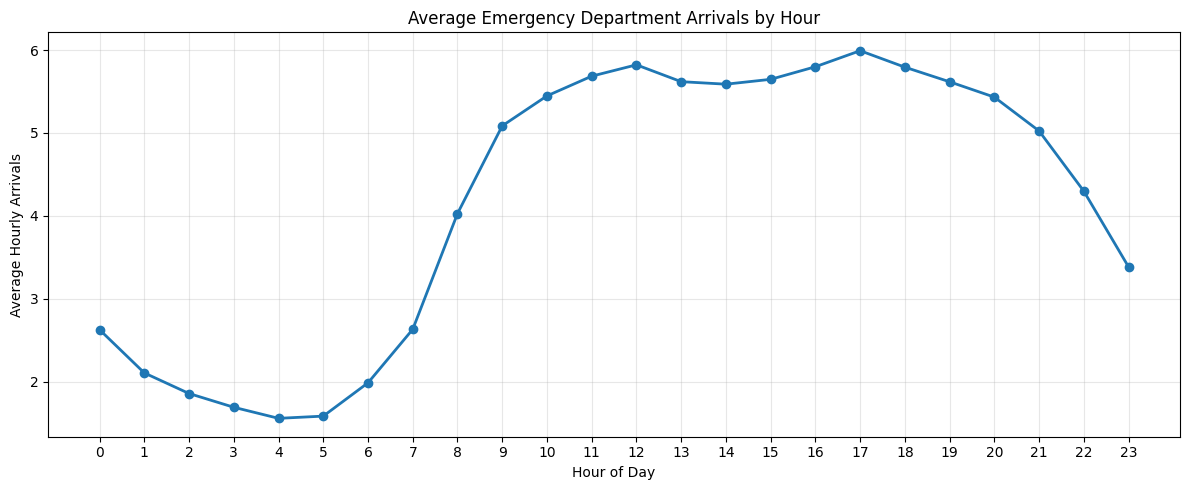

Peak demand hour: 17
Highest average arrivals: 5.99

Lowest demand hour: 4
Lowest average arrivals: 1.56


In [105]:
import matplotlib.pyplot as plt

# Use observed arrival counts only
df_temporal = df_check[
    df_check["arrivals"].notna()
].copy()

# Calculate average arrivals by hour
hourly_avg = (
    df_temporal.groupby("hour")["arrivals"]
    .mean()
    .reindex(range(24))
)

# Plot hourly demand
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_avg.index,
    hourly_avg.values,
    marker="o",
    linewidth=2
)

plt.title("Average Emergency Department Arrivals by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Hourly Arrivals")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Display peak and lowest-demand hours
print("Peak demand hour:", hourly_avg.idxmax())
print("Highest average arrivals:", round(hourly_avg.max(), 2))

print("\nLowest demand hour:", hourly_avg.idxmin())
print("Lowest average arrivals:", round(hourly_avg.min(), 2))

**Observation:** The hourly analysis reveals a clear daily pattern in emergency-department arrivals. The highest average demand occurs at 5 PM, with approximately 5.99 arrivals per hour, while the lowest occurs at 4 AM, with approximately 1.56 arrivals per hour. Arrivals increase during the morning and remain relatively high throughout the afternoon before declining at night. These findings suggest that hour-of-day and cyclical time features may be useful predictors of emergency-department demand.

### Step 6: Day-of-Week and Weekend Demand Analysis

This analysis examines variations in emergency-department arrivals across different days of the week. It also compares average hourly arrivals between weekdays and weekends. The objective is to identify weekly demand patterns and assess the potential usefulness of day-of-week and weekend features for high-demand prediction.

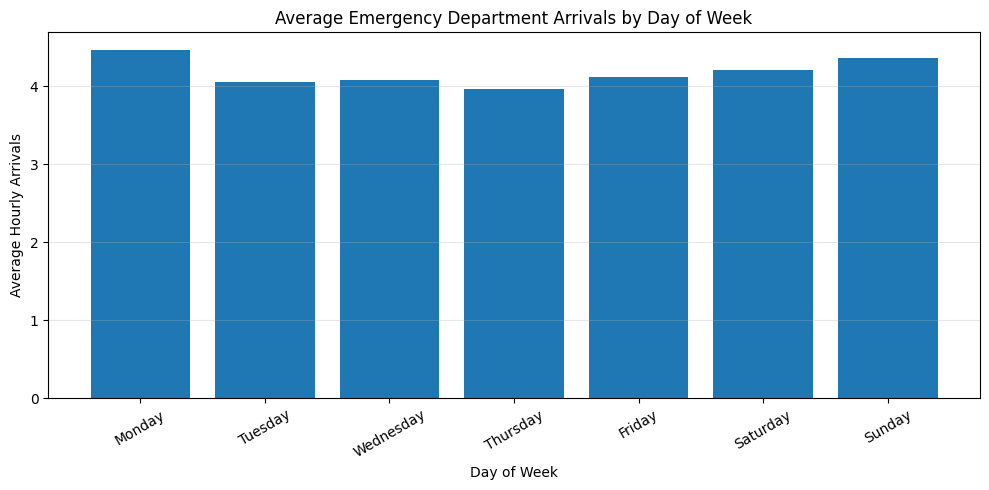

Highest-demand day: Monday
Highest average arrivals: 4.47

Lowest-demand day: Thursday
Lowest average arrivals: 3.96


In [106]:
# Step 6: Day-of-Week and Weekend Demand Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use records with known arrival counts
df_weekly = df_check[
    df_check["arrivals"].notna()
].copy()

# Day names in chronological order
day_names = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Calculate average hourly arrivals for each day
weekly_avg = (
    df_weekly.groupby("day_of_week")["arrivals"]
    .mean()
    .reindex(range(7))
)

# Plot day-of-week demand
plt.figure(figsize=(10, 5))

plt.bar(day_names, weekly_avg.values)

plt.title("Average Emergency Department Arrivals by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Hourly Arrivals")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Display highest and lowest demand days
print("Highest-demand day:", day_names[weekly_avg.idxmax()])
print("Highest average arrivals:", round(weekly_avg.max(), 2))

print("\nLowest-demand day:", day_names[weekly_avg.idxmin()])
print("Lowest average arrivals:", round(weekly_avg.min(), 2))

Average hourly arrivals:


,Average Arrivals
Day_Type,
Weekday,4.134818
Weekend,4.287459


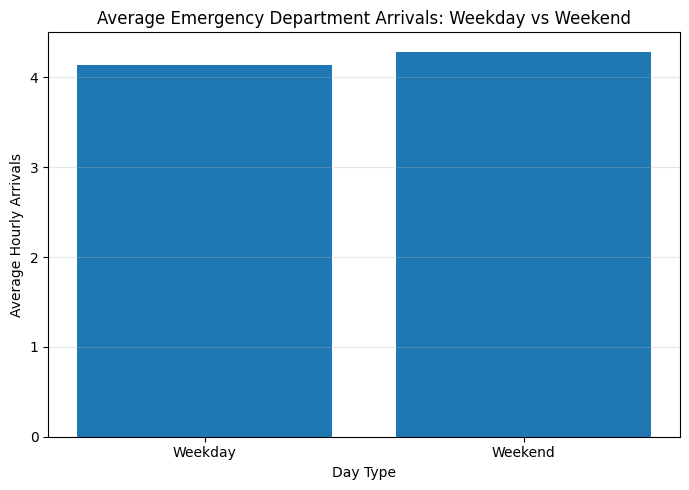

In [107]:
# Compare weekday and weekend arrivals

df_weekly["Day_Type"] = np.where(
    df_weekly["day_of_week"] < 5,
    "Weekday",
    "Weekend"
)

weekend_avg = (
    df_weekly.groupby("Day_Type")["arrivals"]
    .mean()
    .reindex(["Weekday", "Weekend"])
)

print("Average hourly arrivals:")
display(weekend_avg.to_frame(name="Average Arrivals"))

# Plot weekday vs weekend comparison
plt.figure(figsize=(7, 5))

plt.bar(
    weekend_avg.index,
    weekend_avg.values
)

plt.title("Average Emergency Department Arrivals: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Hourly Arrivals")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Observation:** The day-of-week analysis shows that Monday has the highest average hourly emergency-department arrivals (4.47), while Thursday has the lowest (3.96). Weekend hours have slightly higher average arrivals (4.29) than weekday hours (4.13). Although these differences are relatively small compared with the hourly demand variations, they indicate that weekly temporal patterns may provide additional information for predicting emergency-department demand. These findings support investigating day-of-week and weekend features during model evaluation.

### Step 7: Historical Feature Relevance Analysis

This analysis examines the relationships between historical arrival features and current emergency-department arrivals. Pearson correlation is used to identify which lag and rolling-statistical features have stronger linear associations with observed demand.

The analysis is restricted to the training period (2014–2015) to avoid using validation or test data during feature assessment.

Historical Feature Correlation Analysis


,Feature,Correlation with Arrivals
0,same_hour_mean_7d,0.537
1,rolling_mean_3,0.421
2,lag_1,0.368
3,lag_168,0.367
4,lag_24,0.367
5,lag_2,0.326
6,rolling_mean_6,0.310
7,lag_3,0.258
8,rolling_mean_24,0.083
9,rolling_max_24,0.045


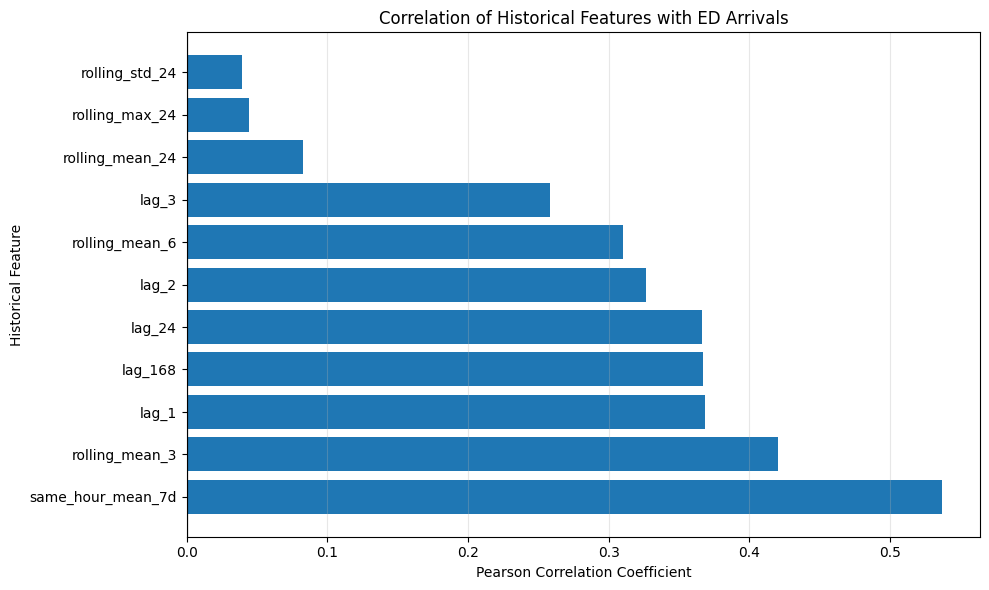

In [108]:
# Step 7: Analyze historical feature correlations

import pandas as pd
import matplotlib.pyplot as plt

# Use only training-period observations
df_relevance = df_check[
    (df_check["split"] == "train") &
    (df_check["arrivals"].notna())
].copy()

historical_features = [
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_24",
    "lag_168",
    "rolling_mean_3",
    "rolling_mean_6",
    "rolling_mean_24",
    "rolling_std_24",
    "rolling_max_24",
    "same_hour_mean_7d"
]

# Calculate correlations with actual arrivals
feature_correlations = (
    df_relevance[historical_features + ["arrivals"]]
    .corr(method="pearson")["arrivals"]
    .drop("arrivals")
    .sort_values(ascending=False)
)

correlation_table = pd.DataFrame({
    "Feature": feature_correlations.index,
    "Correlation with Arrivals": feature_correlations.values
})

print("Historical Feature Correlation Analysis")
display(correlation_table.round(3))

# Visualize correlations
plt.figure(figsize=(10, 6))

plt.barh(
    feature_correlations.index,
    feature_correlations.values
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Correlation of Historical Features with ED Arrivals")
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Historical Feature")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Observation:** The training-period correlation analysis shows that `same_hour_mean_7d` has the strongest positive linear relationship with emergency-department arrivals (r = 0.537), followed by `rolling_mean_3` (r = 0.421). The previous-hour, previous-day, and previous-week lag features also demonstrate positive correlations. In contrast, the 24-hour rolling statistics have relatively weak linear relationships with current arrivals. These findings suggest that historical demand at comparable hours and recent arrival patterns may be informative for predicting emergency-department demand. However, correlation alone does not establish predictive importance, so the features should be evaluated through time-based model validation.

### Step 8: Historical Feature Analysis for High-Demand Prediction

This analysis compares historical feature values between normal-demand and high-demand hours using the corrected v2 dataset. Only training-period observations (2014–2015) are included to avoid using validation or test data during exploratory feature assessment.

The objective is to determine whether historical demand features exhibit differences between the two classes and assess their potential relevance for high-demand classification.

In [109]:
# Step 8: Compare historical features by demand class

import pandas as pd
import matplotlib.pyplot as plt

# Use only training records with known targets
df_high_demand = df_check[
    (df_check["split"] == "train") &
    (df_check["arrivals"].notna()) &
    (df_check["high_demand"].notna())
].copy()

# Select representative engineered features
selected_features = [
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_3",
    "rolling_mean_24",
    "same_hour_mean_7d"
]

# Compare average feature values between classes
feature_comparison = (
    df_high_demand.groupby("high_demand")[selected_features]
    .mean()
    .T
)

feature_comparison.columns = [
    "Normal Demand",
    "High Demand"
]

feature_comparison["Difference"] = (
    feature_comparison["High Demand"] -
    feature_comparison["Normal Demand"]
)

print("Historical Feature Comparison by Demand Class")
display(feature_comparison.round(3))

print("\nNumber of observations by demand class:")
print(df_high_demand["high_demand"].value_counts().sort_index())

Historical Feature Comparison by Demand Class


,Normal Demand,High Demand,Difference
lag_1,3.758,5.036,1.278
lag_24,3.749,5.254,1.505
lag_168,3.742,5.153,1.410
rolling_mean_3,3.762,4.981,1.219
rolling_mean_24,3.813,3.915,0.102
same_hour_mean_7d,3.749,5.142,1.393



Number of observations by demand class:
high_demand
0.0    16214
1.0      802
Name: count, dtype: int64


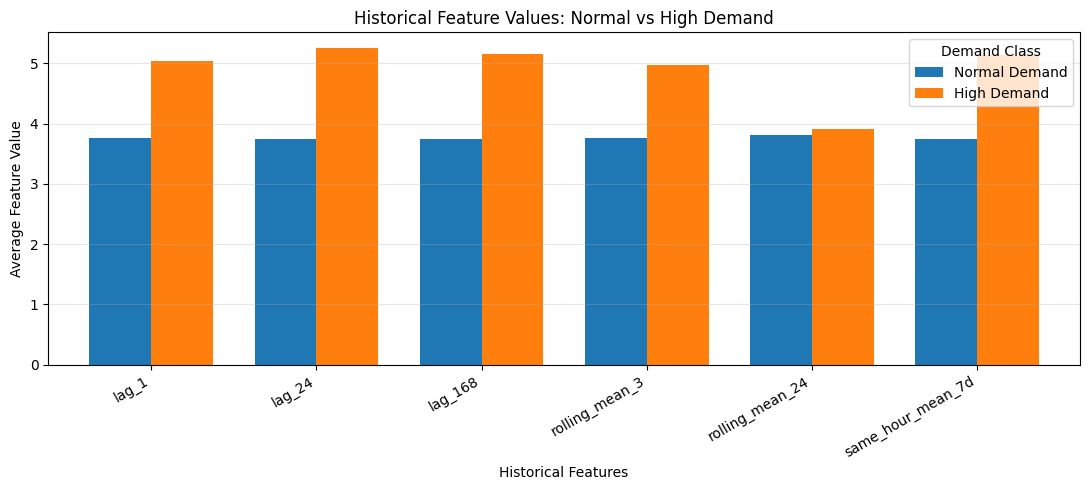

In [110]:
# Visualize selected feature differences between classes

plot_features = [
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_3",
    "rolling_mean_24",
    "same_hour_mean_7d"
]

plot_data = feature_comparison.loc[
    plot_features,
    ["Normal Demand", "High Demand"]
]

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.75
)

plt.title("Historical Feature Values: Normal vs High Demand")
plt.xlabel("Historical Features")
plt.ylabel("Average Feature Value")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Demand Class")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Observation:** The training-period analysis shows that historical arrival features generally have higher average values during high-demand hours than during normal-demand hours. The largest difference occurs for `lag_24` (1.505 arrivals), followed by `lag_168` (1.410) and `same_hour_mean_7d` (1.393). In contrast, `rolling_mean_24` shows a relatively small difference (0.102). These findings suggest that previous-day, previous-week, and recent-arrival features may be informative for high-demand classification. The training data also exhibits substantial class imbalance, with 802 high-demand observations compared with 16,214 normal-demand observations. Therefore, recall, precision, F1-score, and PR-AUC will be important when evaluating classification performance.

### Step 9: Feature Engineering Summary and Model-Readiness Assessment

This section summarizes the validation and exploratory analysis of the corrected v2 time-series features.

The analysis focuses on feature correctness, missing-value handling, temporal demand patterns, and the relevance of historical features for high-demand classification.

The objective is to provide recommendations for the team's subsequent model training and evaluation.

In [111]:
# Step 9: Feature Engineering Summary

summary = pd.DataFrame({
    "Assessment": [
        "Hourly timeline",
        "Lag features",
        "Rolling/statistical features",
        "Same-hour 7-day feature",
        "Highest missingness",
        "Lowest missingness",
        "Strongest arrival correlation",
        "Largest high-demand class difference"
    ],
    "Finding": [
        "Complete hourly timeline verified",
        "5 lag features validated",
        "5 rolling features validated",
        "Validated with minimum 4 historical observations",
        "rolling_mean_24 / rolling_std_24 / rolling_max_24",
        "same_hour_mean_7d",
        "same_hour_mean_7d",
        "lag_24"
    ],
    "Result": [
        "PASS",
        "0 mismatches",
        "0 mismatches",
        "0 mismatches",
        "5.97% missing",
        "0.27% missing",
        "r = 0.537",
        "+1.505 arrivals"
    ]
})

print("Feature Engineering Assessment Summary")
display(summary)

Feature Engineering Assessment Summary


,Assessment,Finding,Result
0,Hourly timeline,Complete hourly timeline verified,PASS
1,Lag features,5 lag features validated,0 mismatches
2,Rolling/statistical features,5 rolling features validated,0 mismatches
3,Same-hour 7-day feature,Validated with minimum 4 historical observations,0 mismatches
4,Highest missingness,rolling_mean_24 / rolling_std_24 / rolling_max_24,5.97% missing
5,Lowest missingness,same_hour_mean_7d,0.27% missing
6,Strongest arrival correlation,same_hour_mean_7d,r = 0.537
7,Largest high-demand class difference,lag_24,+1.505 arrivals


### Feature Engineering Findings and Recommendations

The corrected v2 dataset contains 35,040 hourly records and includes time-based, lag, and rolling-statistical features for predicting emergency-department demand. Independent validation confirmed that all five lag features and six rolling/statistical features match their expected historical calculations.

The missing-value analysis identified higher missingness in the 24-hour rolling features (5.97%) compared with other engineered features. These missing values should be handled appropriately during model preparation rather than automatically replaced with zero.

Exploratory analysis revealed substantial hourly demand variation, with the highest average arrivals at 5 PM and the lowest at 4 AM. Weekly variation was comparatively modest.

Among the historical features examined, `same_hour_mean_7d` demonstrated the strongest linear correlation with arrivals (r = 0.537). The previous-day lag (`lag_24`) exhibited the largest average difference between high-demand and normal-demand hours (1.505 arrivals).

**Recommendations for subsequent modeling:**

1. Retain historical lag and rolling features as candidates for model training.
2. Compare feature availability and handle missing values without using future observations.
3. Use the shared chronological training, validation, and testing split.
4. Evaluate classification performance using recall, precision, F1-score, and PR-AUC because the high-demand class is substantially underrepresented.
5. Investigate feature importance and predictive performance using time-based validation before deciding whether to exclude weaker features.

These recommendations support the next modeling phase without changing the shared v2 preprocessing pipeline.

# 1.4 Baselines and Model Development

**Input:** `ed_hourly_clean.csv` from the shared v2 data pipeline.
**Task:** one-hour-ahead alert — predict whether hour *t* is a high-demand hour using only information available before *t*.

| Section | WBS | Content |
|---|---|---|
| 1 | — | Setup, data, feature sets, evaluation utilities |
| 2 | 1.4.1 | Rule baselines: previous week, last hour, hour-of-week frequency |
| 3 | 1.4.2 | ARIMA alert baseline (harmonic default; Choudhury & Urena SARIMA optional) → probability of exceeding the threshold |
| 4 | 1.4.3–1.4.6 | Logistic Regression, KNN, SVM (linear + RBF), XGBoost |
| 5 | — | Comparison on validation (2016) and test (2017) |
| 6 | — | Feature importance |
| 7 | — | Export predictions for tuning (1.5) and evaluation (1.6) |

**Protocol.**
* Hyperparameters: `TimeSeriesSplit` inside the training period (2014–2015), scored by PR-AUC.
* Models are fit on training data only. Validation (2016) is used to choose a probability cutoff; test (2017) is touched once.
* Each model is reported at the default cutoff (0.5, or the rule itself) and at a **preliminary** validation-tuned cutoff (max F1). Final cutoff tuning, SMOTE, and resampling are in 1.5.

## 1. Setup

In [112]:
import os, sys, json, time, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

for pkg in ("xgboost", "statsmodels"):
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160)

# ---------------- Configuration ----------------
CSV_NAME     = os.environ.get("ED_CSV", "ed_hourly_clean.csv")
RANDOM_STATE = 42
N_SPLITS     = 4          # TimeSeriesSplit folds inside the training period
SVM_SUBSAMPLE = 8000      # RBF SVM is O(n^2); fit on a time-ordered stratified subsample
XGB_N_ITER   = 12         # random-search iterations for XGBoost
ARIMA_SPEC   = "harmonic" # "harmonic": ARIMA(3,0,0) errors + daily/weekly/yearly Fourier terms (fast, ~1 min)
                          # "paper":    SARIMA(3,0,0)(2,1,0)[24] of Choudhury & Urena (2020) (slow, ~10+ min)
ARIMA_ORDER  = (3, 0, 0)
PAPER_SEASONAL, PAPER_FIT_WEEKS = (2, 1, 0, 24), 8   # paper spec is fit on the last 8 training weeks

CSV = next((p for p in (CSV_NAME, f"/content/{CSV_NAME}", f"data/{CSV_NAME}") if os.path.exists(p)), None)
assert CSV, "ed_hourly_clean.csv not found — run the v2 data pipeline first or upload the file."
print("Using", CSV)

Using ed_hourly_clean.csv


In [113]:
data = pd.read_csv(CSV, parse_dates=["datetime"]).sort_values("datetime").reset_index(drop=True)

# Threshold implied by the label: largest arrival count labelled as normal demand
THRESHOLD = data.loc[data["high_demand"] == 0, "arrivals"].max()

model = data[data["high_demand"].notna()].copy()
model["y"] = model["high_demand"].astype(int)
is_tr, is_va, is_te = (model["split"] == s for s in ("train", "validation", "test"))
VAL_START = model.loc[is_va, "datetime"].min()

print(f"High demand = arrivals > {THRESHOLD}")
(model.groupby("split", sort=False)
      .agg(start=("datetime", "min"), end=("datetime", "max"), hours=("y", "size"),
           positives=("y", "sum"), positive_rate=("y", "mean"))
      .assign(positive_rate=lambda d: (d["positive_rate"] * 100).round(2)))

High demand = arrivals > 8.0


,start,end,hours,positives,positive_rate
split,,,,,
train,2014-01-01,2015-12-30 23:00:00,17016,802,4.71
validation,2016-01-01,2016-12-30 23:00:00,8496,629,7.40
test,2017-01-01,2017-12-30 23:00:00,8472,983,11.60


In [114]:
CALENDAR_RAW = ["hour", "day_of_week", "month", "is_weekend", "is_holiday"]
CALENDAR_CYC = ["hour_sin", "hour_cos", "day_of_week_sin", "day_of_week_cos",
                "month_sin", "month_cos", "is_weekend", "is_holiday"]
LAGS = ["lag_1", "lag_2", "lag_3", "lag_24", "lag_168",
        "rolling_mean_3", "rolling_mean_6", "rolling_mean_24",
        "rolling_std_24", "rolling_max_24", "same_hour_mean_7d"]

TREE_FEATURES   = CALENDAR_RAW + LAGS           # XGBoost: raw calendar, NaN handled natively
DIST_FEATURES   = CALENDAR_CYC + LAGS           # KNN / SVM: cyclical encodings, scaled
LINEAR_NUMERIC  = CALENDAR_CYC + LAGS           # Logistic Regression numeric part
LINEAR_CATEG    = ["hour", "day_of_week"]       # + one-hot hour and weekday

X_tr, y_tr = model.loc[is_tr], model.loc[is_tr, "y"].to_numpy()
X_va, y_va = model.loc[is_va], model.loc[is_va, "y"].to_numpy()
X_te, y_te = model.loc[is_te], model.loc[is_te, "y"].to_numpy()
tscv = TimeSeriesSplit(n_splits=N_SPLITS)
print("train / validation / test:", len(X_tr), len(X_va), len(X_te))

train / validation / test: 17016 8496 8472


In [115]:
RESULTS, SCORES, BEST_PARAMS = [], {}, {}
PRED = {"validation": model.loc[is_va, ["datetime", "arrivals", "y"]].reset_index(drop=True),
        "test":       model.loc[is_te, ["datetime", "arrivals", "y"]].reset_index(drop=True)}

def evaluate(y, score, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"recall": recall_score(y, pred, zero_division=0),
            "precision": precision_score(y, pred, zero_division=0),
            "f1": f1_score(y, pred, zero_division=0),
            "pr_auc": average_precision_score(y, score),
            "alerts_per_day": pred.mean() * 24,
            "tp": tp, "fp": fp, "fn": fn, "tn": tn}

def best_f1_cutoff(y, score):
    p, r, t = precision_recall_curve(y, score)
    f = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return t[np.nanargmax(f)]

def record(name, score_va, score_te, pred_va=None, pred_te=None, default_cutoff=0.5):
    # Logs metrics at the default cutoff (or the rule's own prediction) and at a validation-tuned cutoff.
    score_va, score_te = np.asarray(score_va, float), np.asarray(score_te, float)
    tuned = best_f1_cutoff(y_va, score_va)
    for split, y, s, p in (("validation", y_va, score_va, pred_va), ("test", y_te, score_te, pred_te)):
        p_default = (s >= default_cutoff).astype(int) if p is None else np.asarray(p, int)
        RESULTS.append({"model": name, "split": split, "cutoff": "default", "cutoff_value": default_cutoff if p is None else np.nan,
                        **evaluate(y, s, p_default)})
        RESULTS.append({"model": name, "split": split, "cutoff": "val-tuned (prelim.)", "cutoff_value": tuned,
                        **evaluate(y, s, (s >= tuned).astype(int))})
        PRED[split][f"score_{name}"] = s
    SCORES[name] = (score_va, score_te)
    row = pd.DataFrame(RESULTS)
    show = row[(row["model"] == name)].set_index(["split", "cutoff"])
    return show[["recall", "precision", "f1", "pr_auc", "alerts_per_day"]].round(3)

def tune(name, estimator, grid, X, y, n_iter=None):
    t0 = time.time()
    Search = RandomizedSearchCV if n_iter else GridSearchCV
    kw = {"n_iter": n_iter, "random_state": RANDOM_STATE} if n_iter else {}
    search = Search(estimator, grid, scoring="average_precision", cv=tscv, n_jobs=-1, refit=True, **kw)
    search.fit(X, y)
    BEST_PARAMS[name] = {k: (v.item() if hasattr(v, "item") else v) for k, v in search.best_params_.items()}
    print(f"{name}: best CV PR-AUC = {search.best_score_:.3f} | {BEST_PARAMS[name]} | {time.time() - t0:.0f}s")
    return search.best_estimator_

## 2. Rule baselines (1.4.1)

* **Previous week:** alert if the same hour last week exceeded the threshold (`lag_168 > threshold`). Score for PR-AUC: `lag_168`.
* **Last hour (persistence):** alert if the previous hour exceeded the threshold. Score: `lag_1`.
* **Hour-of-week frequency:** probability = share of training hours with the same weekday × hour that were high demand. This is the strongest "no learning" baseline, because hour of day dominates the signal.

In [116]:
def rule_scores(col):
    fill = X_tr[col].median()
    s_va, s_te = X_va[col].fillna(fill).to_numpy(), X_te[col].fillna(fill).to_numpy()
    return s_va, s_te, (s_va > THRESHOLD).astype(int), (s_te > THRESHOLD).astype(int)

s_va, s_te, p_va, p_te = rule_scores("lag_168")
display(record("rule_prev_week", s_va, s_te, p_va, p_te))

s_va, s_te, p_va, p_te = rule_scores("lag_1")
display(record("rule_last_hour", s_va, s_te, p_va, p_te))

freq = X_tr.assign(y=y_tr).groupby(["day_of_week", "hour"])["y"].mean()
how = lambda X: X.set_index(["day_of_week", "hour"]).index.map(freq).to_numpy(dtype=float)
display(record("hour_of_week_freq", how(X_va), how(X_te)))

recall  precision     f1  pr_auc  alerts_per_day
split      cutoff                                                               
validation default               0.146      0.154  0.150   0.128           1.684
           val-tuned (prelim.)   0.566      0.138  0.221   0.128           7.308
test       default               0.192      0.197  0.194   0.181           2.722
           val-tuned (prelim.)   0.601      0.190  0.288   0.181           8.833

recall  precision     f1  pr_auc  alerts_per_day
split      cutoff                                                               
validation default               0.146      0.146  0.146   0.122           1.777
           val-tuned (prelim.)   0.539      0.126  0.204   0.122           7.627
test       default               0.202      0.202  0.202   0.181           2.785
           val-tuned (prelim.)   0.613      0.188  0.288   0.181           9.071

recall  precision     f1  pr_auc  alerts_per_day
split      cutoff                                                               
validation default               0.000      0.000  0.000   0.148           0.000
           val-tuned (prelim.)   0.528      0.157  0.242   0.148           5.972
test       default               0.000      0.000  0.000   0.218           0.000
           val-tuned (prelim.)   0.480      0.221  0.303   0.218           6.037

## 3. ARIMA alert baseline (1.4.2)

1. Fit an ARIMA model on training-period hourly counts. Missing hours are handled by the Kalman filter.
   * **Default (`ARIMA_SPEC = "harmonic"`)**: ARIMA(3,0,0) errors with a constant, linear trend, and Fourier terms for daily (24 h), weekly (168 h), and yearly seasonality ("dynamic harmonic regression"). Hourly data has very long seasonal periods; Fourier regressors capture them at a fraction of the cost of seasonal AR terms. Fit on all of 2014–2015 in about a minute.
   * **Optional (`"paper"`)**: `SARIMA(3,0,0)(2,1,0)[24]` reported by Choudhury & Urena (2020), plus weekly Fourier terms. Its state space has ~75 states, so it is fit on the last `PAPER_FIT_WEEKS` training weeks and takes much longer. Use it to replicate the benchmark.
2. Keep the parameters fixed and filter through 2016–2017 to get **one-step-ahead** forecasts μ̂ₜ and their variance σ̂ₜ² (no refitting, no look-ahead).
3. Convert each forecast to an alert probability: **P(Yₜ > threshold) = 1 − Φ((threshold + 0.5 − μ̂ₜ) / σ̂ₜ)** (normal approximation with continuity correction). This gives ARIMA a continuous score, so it is compared on PR-AUC like every classifier.
4. Also report RMSE (vs. the 1.55 benchmark) and Ljung–Box residual tests.

In [117]:
series = data.set_index("datetime")["arrivals"].asfreq("h")
t = np.arange(len(series))

def fourier(period, K, tag):
    return {f"{tag}_{f}{k}": fn(2 * np.pi * k * t / period)
            for k in range(1, K + 1) for f, fn in (("sin", np.sin), ("cos", np.cos))}

if ARIMA_SPEC == "harmonic":
    exog = pd.DataFrame({**fourier(24, 4, "day"), **fourier(168, 4, "week"), **fourier(8766, 2, "year"),
                         "trend": t / 8766}, index=series.index)
    seasonal, trend = (0, 0, 0, 0), "c"
    fit_start = series.index.min()
    apply_start = series.index.min()
else:
    exog = pd.DataFrame(fourier(168, 3, "week"), index=series.index)
    seasonal, trend = PAPER_SEASONAL, "n"
    fit_start = VAL_START - pd.Timedelta(weeks=PAPER_FIT_WEEKS)
    apply_start = VAL_START - pd.Timedelta(days=14)    # burn-in before the validation period

fit_mask = (series.index >= fit_start) & (series.index < VAL_START)
t0 = time.time()
sarima_res = SARIMAX(series[fit_mask], exog=exog[fit_mask], order=ARIMA_ORDER,
                     seasonal_order=seasonal, trend=trend).fit(disp=False, maxiter=200)
print(f"ARIMA ({ARIMA_SPEC}) fitted in {time.time() - t0:.0f}s on {fit_mask.sum():,} hours | AIC = {sarima_res.aic:,.1f}")
print(sarima_res.summary().tables[1])

ARIMA (harmonic) fitted in 74s on 17,520 hours | AIC = 72,228.6
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      3.1353      0.053     59.194      0.000       3.032       3.239
day_sin1      -1.5468      0.028    -54.830      0.000      -1.602      -1.492
day_cos1      -1.3009      0.026    -49.989      0.000      -1.352      -1.250
day_sin2      -0.5706      0.026    -22.317      0.000      -0.621      -0.521
day_cos2       0.1242      0.026      4.762      0.000       0.073       0.175
day_sin3       0.2036      0.024      8.482      0.000       0.157       0.251
day_cos3      -0.0355      0.024     -1.463      0.144      -0.083       0.012
day_sin4      -0.0396      0.022     -1.780      0.075      -0.083       0.004
day_cos4      -0.1595      0.022     -7.192      0.000      -0.203      -0.116
week_sin1     -0.1673      0.024     -6.893      0.000      -0.215 

In [118]:
apply_mask = series.index >= apply_start
sarima_all = sarima_res.apply(series[apply_mask], exog=exog[apply_mask])   # same parameters, filter forward
fc = sarima_all.get_prediction(start=VAL_START)
arima = pd.DataFrame({"mu": fc.predicted_mean, "sigma": np.sqrt(fc.var_pred_mean)})
arima["prob"] = 1 - norm.cdf((THRESHOLD + 0.5 - arima["mu"]) / arima["sigma"])

a_va = arima.reindex(X_va["datetime"])
a_te = arima.reindex(X_te["datetime"])
assert a_va["prob"].notna().all() and a_te["prob"].notna().all()

for split, X, a in (("validation", X_va, a_va), ("test", X_te, a_te)):
    err = X["arrivals"].to_numpy() - a["mu"].to_numpy()
    print(f"{split:<10} one-step RMSE = {np.sqrt(np.mean(err ** 2)):.3f} | ME = {err.mean():+.3f}   (benchmark RMSE 1.55)")
    PRED[split]["arima_forecast"] = a["mu"].to_numpy()

display(record("arima", a_va["prob"], a_te["prob"]))

resid = sarima_res.resid.iloc[24 * 8:].dropna()   # drop the differencing burn-in
print("Ljung–Box on training residuals:")
print(acorr_ljungbox(resid, lags=[24, 168]).round(4))

validation one-step RMSE = 2.098 | ME = +0.013   (benchmark RMSE 1.55)
test       one-step RMSE = 2.256 | ME = +0.169   (benchmark RMSE 1.55)


recall  precision     f1  pr_auc  alerts_per_day
split      cutoff                                                               
validation default               0.000      0.000  0.000   0.173           0.000
           val-tuned (prelim.)   0.669      0.158  0.255   0.173           7.545
test       default               0.000      0.000  0.000   0.236           0.000
           val-tuned (prelim.)   0.832      0.210  0.335   0.236          11.034

Ljung–Box on training residuals:
      lb_stat  lb_pvalue
24    30.8009     0.1596
168  196.2460     0.0671


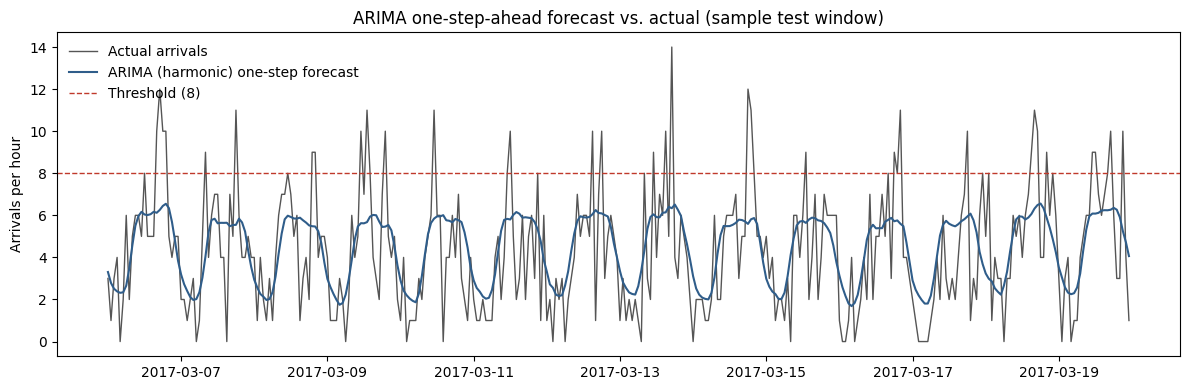

In [119]:
# Visual check: two weeks of the 2017 test period
win = slice("2017-03-06", "2017-03-19")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(series[win].index, series[win], color="#555", lw=1, label="Actual arrivals")
ax.plot(arima.loc[win].index, arima.loc[win, "mu"], color="#2f5d8a", lw=1.5, label=f"ARIMA ({ARIMA_SPEC}) one-step forecast")
ax.axhline(THRESHOLD, color="#c0392b", ls="--", lw=1, label=f"Threshold ({THRESHOLD:g})")
ax.set_ylabel("Arrivals per hour"); ax.legend(loc="upper left", frameon=False)
ax.set_title("ARIMA one-step-ahead forecast vs. actual (sample test window)")
plt.tight_layout(); plt.show()

## 4. Machine-learning classifiers (1.4.3–1.4.6)

Class imbalance is handled with class weights (`class_weight="balanced"` / `scale_pos_weight`). KNN has no class weights, so it relies on the cutoff. Missing lag values are imputed with training medians inside each pipeline (fit on training folds only); XGBoost uses NaN natively.

In [120]:
num_pipe = lambda: Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])

linear_pre = ColumnTransformer([("num", num_pipe(), LINEAR_NUMERIC),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), LINEAR_CATEG)])
dist_pre = ColumnTransformer([("num", num_pipe(), DIST_FEATURES)])

### 4.1 Logistic Regression (1.4.3)

In [121]:
lr = tune("logistic_regression",
          Pipeline([("pre", linear_pre), ("clf", LogisticRegression(class_weight="balanced", max_iter=3000))]),
          {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3]}, X_tr, y_tr)
record("logistic_regression", lr.predict_proba(X_va)[:, 1], lr.predict_proba(X_te)[:, 1])

logistic_regression: best CV PR-AUC = 0.106 | {'clf__C': 0.03} | 3s


recall  precision     f1  pr_auc  alerts_per_day
split      cutoff                                                               
validation default               0.925      0.134  0.235   0.170          12.229
           val-tuned (prelim.)   0.698      0.159  0.259   0.170           7.814
test       default               0.928      0.201  0.331   0.235          12.841
           val-tuned (prelim.)   0.736      0.213  0.330   0.235           9.620

### 4.2 K-Nearest Neighbors (1.4.4)

In [122]:
knn = tune("knn",
           Pipeline([("pre", dist_pre), ("clf", KNeighborsClassifier())]),
           {"clf__n_neighbors": [25, 51, 101, 201], "clf__weights": ["uniform", "distance"]}, X_tr, y_tr)
record("knn", knn.predict_proba(X_va)[:, 1], knn.predict_proba(X_te)[:, 1])

knn: best CV PR-AUC = 0.102 | {'clf__n_neighbors': 201, 'clf__weights': 'distance'} | 7s


recall  precision     f1  pr_auc  alerts_per_day
split      cutoff                                                               
validation default               0.000      0.000  0.000   0.153           0.000
           val-tuned (prelim.)   0.685      0.146  0.240   0.153           8.367
test       default               0.000      0.000  0.000   0.215           0.000
           val-tuned (prelim.)   0.744      0.205  0.321   0.215          10.125

### 4.3 Support Vector Machine (1.4.5)

* **Linear SVM** on all training data, probabilities via sigmoid (Platt) calibration.
* **RBF SVM** on a time-ordered, stratified subsample of `SVM_SUBSAMPLE` training hours (kernel SVM scales quadratically). Tuned on the decision function, then wrapped in sigmoid (Platt) calibration to output probabilities.

In [123]:
svm_lin = tune("svm_linear",
               Pipeline([("pre", linear_pre),
                         ("clf", CalibratedClassifierCV(LinearSVC(class_weight="balanced", max_iter=20000),
                                                        method="sigmoid", cv=3))]),
               {"clf__estimator__C": [0.001, 0.01, 0.1, 1]}, X_tr, y_tr)
record("svm_linear", svm_lin.predict_proba(X_va)[:, 1], svm_lin.predict_proba(X_te)[:, 1])

svm_linear: best CV PR-AUC = 0.107 | {'clf__estimator__C': 0.01} | 2s


recall  precision     f1  pr_auc  alerts_per_day
split      cutoff                                                               
validation default               0.000      0.000  0.000   0.166           0.000
           val-tuned (prelim.)   0.652      0.159  0.255   0.166           7.302
test       default               0.000      0.000  0.000   0.233           0.000
           val-tuned (prelim.)   0.683      0.217  0.330   0.233           8.745

In [124]:
rng = np.random.default_rng(RANDOM_STATE)
n = min(SVM_SUBSAMPLE, len(X_tr))
pos, neg = np.flatnonzero(y_tr == 1), np.flatnonzero(y_tr == 0)
n_pos = int(round(n * len(pos) / len(y_tr)))
idx = np.sort(np.concatenate([rng.choice(pos, n_pos, replace=False), rng.choice(neg, n - n_pos, replace=False)]))
X_sub, y_sub = X_tr.iloc[idx], y_tr[idx]

svm_rbf = tune("svm_rbf",
               Pipeline([("pre", dist_pre), ("clf", SVC(kernel="rbf", class_weight="balanced"))]),
               {"clf__C": [0.3, 1, 3], "clf__gamma": ["scale", 0.03]}, X_sub, y_sub)
svm_rbf = CalibratedClassifierCV(svm_rbf, method="sigmoid", cv=3).fit(X_sub, y_sub)   # Platt-scaled probabilities
record("svm_rbf", svm_rbf.predict_proba(X_va)[:, 1], svm_rbf.predict_proba(X_te)[:, 1])

svm_rbf: best CV PR-AUC = 0.087 | {'clf__C': 0.3, 'clf__gamma': 0.03} | 14s


recall  precision     f1  pr_auc  alerts_per_day
split      cutoff                                                               
validation default               0.000      0.000  0.000   0.142           0.000
           val-tuned (prelim.)   0.862      0.134  0.232   0.142          11.444
test       default               0.000      0.000  0.000   0.215           0.000
           val-tuned (prelim.)   0.852      0.199  0.323   0.215          11.926

### 4.4 XGBoost (1.4.6)

In [125]:
spw = (y_tr == 0).sum() / (y_tr == 1).sum()
xgb = tune("xgboost",
           XGBClassifier(objective="binary:logistic", eval_metric="aucpr", tree_method="hist",
                         scale_pos_weight=spw, random_state=RANDOM_STATE, n_jobs=-1),
           {"max_depth": [3, 4, 5, 6], "learning_rate": [0.03, 0.05, 0.1],
            "n_estimators": [200, 400, 700], "min_child_weight": [1, 5, 10],
            "subsample": [0.8, 1.0], "colsample_bytree": [0.7, 0.9, 1.0]},
           X_tr[TREE_FEATURES], y_tr, n_iter=XGB_N_ITER)
record("xgboost", xgb.predict_proba(X_va[TREE_FEATURES])[:, 1], xgb.predict_proba(X_te[TREE_FEATURES])[:, 1])

xgboost: best CV PR-AUC = 0.103 | {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.7} | 21s


recall  precision     f1  pr_auc  alerts_per_day
split      cutoff                                                               
validation default               0.757      0.125  0.214   0.137          10.780
           val-tuned (prelim.)   0.690      0.132  0.221   0.137           9.297
test       default               0.595      0.198  0.297   0.208           8.357
           val-tuned (prelim.)   0.512      0.196  0.283   0.208           7.275

## 5. Comparison

PR-AUC is cutoff-free and is the primary ranking metric (the no-skill PR-AUC equals the positive rate). Recall / precision / F1 depend on the cutoff: "default" is 0.5 (or the rule itself); "val-tuned" maximizes F1 on 2016 and is then applied unchanged to 2017.

In [126]:
res = pd.DataFrame(RESULTS)
ORDER = list(SCORES)
def table(split):
    t = res[res["split"] == split].pivot_table(index="model", columns="cutoff",
                                               values=["recall", "precision", "f1", "alerts_per_day"], sort=False)
    t[("pr_auc", "")] = res[res["split"] == split].groupby("model", sort=False)["pr_auc"].first()
    return t.reindex(ORDER).sort_values(("pr_auc", ""), ascending=False).round(3)

print(f"No-skill PR-AUC — validation: {y_va.mean():.3f} | test: {y_te.mean():.3f}")
print("\nVALIDATION (2016)"); display(table("validation"))
print("TEST (2017)");        display(table("test"))

No-skill PR-AUC — validation: 0.074 | test: 0.116

VALIDATION (2016)


recall                     precision                          f1                     alerts_per_day                     pr_auc
cutoff              default val-tuned (prelim.)   default val-tuned (prelim.) default val-tuned (prelim.)        default val-tuned (prelim.)       
model                                                                                                                                              
arima                 0.000               0.669     0.000               0.158   0.000               0.255          0.000               7.545  0.173
logistic_regression   0.925               0.698     0.134               0.159   0.235               0.259         12.229               7.814  0.170
svm_linear            0.000               0.652     0.000               0.159   0.000               0.255          0.000               7.302  0.166
knn                   0.000               0.685     0.000               0.146   0.000               0.240          0.000               8.367  0.153
hour_of_week_freq     0.000               0.528     0.000               0.157   0.000               0.242          0.000               5.972  0.148
svm_rbf               0.000               0.862     0.000               0.134   0.000               0.232          0.000              11.444  0.142
xgboost               0.757               0.690     0.125               0.132   0.214               0.221         10.780               9.297  0.137
rule_prev_week        0.146               0.566     0.154               0.138   0.150               0.221          1.684               7.308  0.128
rule_last_hour        0.146               0.539     0.146               0.126   0.146               0.204          1.777               7.627  0.122

TEST (2017)


recall                     precision                          f1                     alerts_per_day                     pr_auc
cutoff              default val-tuned (prelim.)   default val-tuned (prelim.) default val-tuned (prelim.)        default val-tuned (prelim.)       
model                                                                                                                                              
arima                 0.000               0.832     0.000               0.210   0.000               0.335          0.000              11.034  0.236
logistic_regression   0.928               0.736     0.201               0.213   0.331               0.330         12.841               9.620  0.235
svm_linear            0.000               0.683     0.000               0.217   0.000               0.330          0.000               8.745  0.233
hour_of_week_freq     0.000               0.480     0.000               0.221   0.000               0.303          0.000               6.037  0.218
svm_rbf               0.000               0.852     0.000               0.199   0.000               0.323          0.000              11.926  0.215
knn                   0.000               0.744     0.000               0.205   0.000               0.321          0.000              10.125  0.215
xgboost               0.595               0.512     0.198               0.196   0.297               0.283          8.357               7.275  0.208
rule_last_hour        0.202               0.613     0.202               0.188   0.202               0.288          2.785               9.071  0.181
rule_prev_week        0.192               0.601     0.197               0.190   0.194               0.288          2.722               8.833  0.181

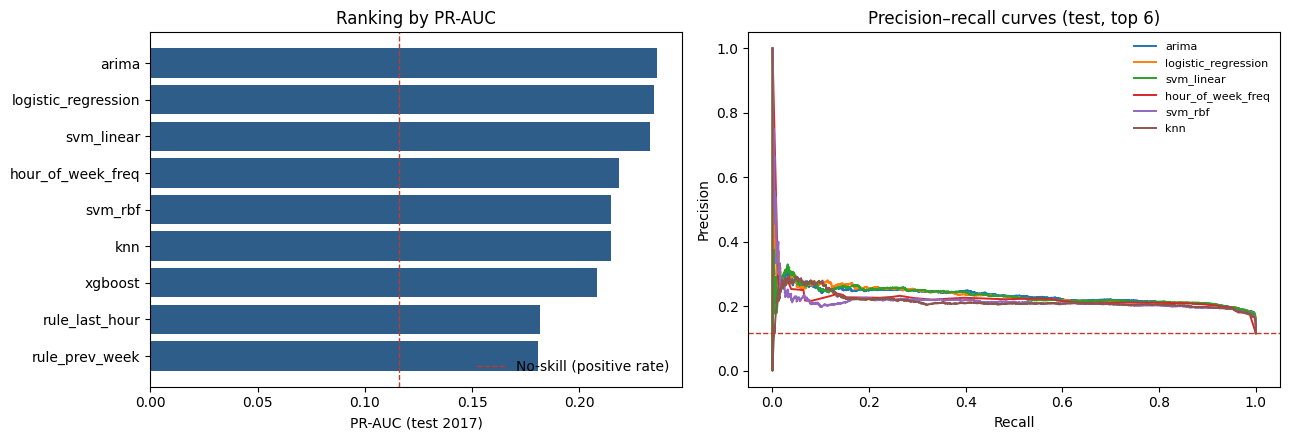

In [127]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
test_pr = res[(res["split"] == "test")].groupby("model", sort=False)["pr_auc"].first().reindex(ORDER).sort_values()
axes[0].barh(test_pr.index, test_pr.values, color="#2f5d8a")
axes[0].axvline(y_te.mean(), color="#c0392b", ls="--", lw=1, label="No-skill (positive rate)")
axes[0].set_xlabel("PR-AUC (test 2017)"); axes[0].legend(frameon=False, loc="lower right")
axes[0].set_title("Ranking by PR-AUC")

for name in test_pr.index[::-1][:6]:
    p, r, _ = precision_recall_curve(y_te, SCORES[name][1])
    axes[1].plot(r, p, lw=1.4, label=name)
axes[1].axhline(y_te.mean(), color="#c0392b", ls="--", lw=1)
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision–recall curves (test, top 6)")
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

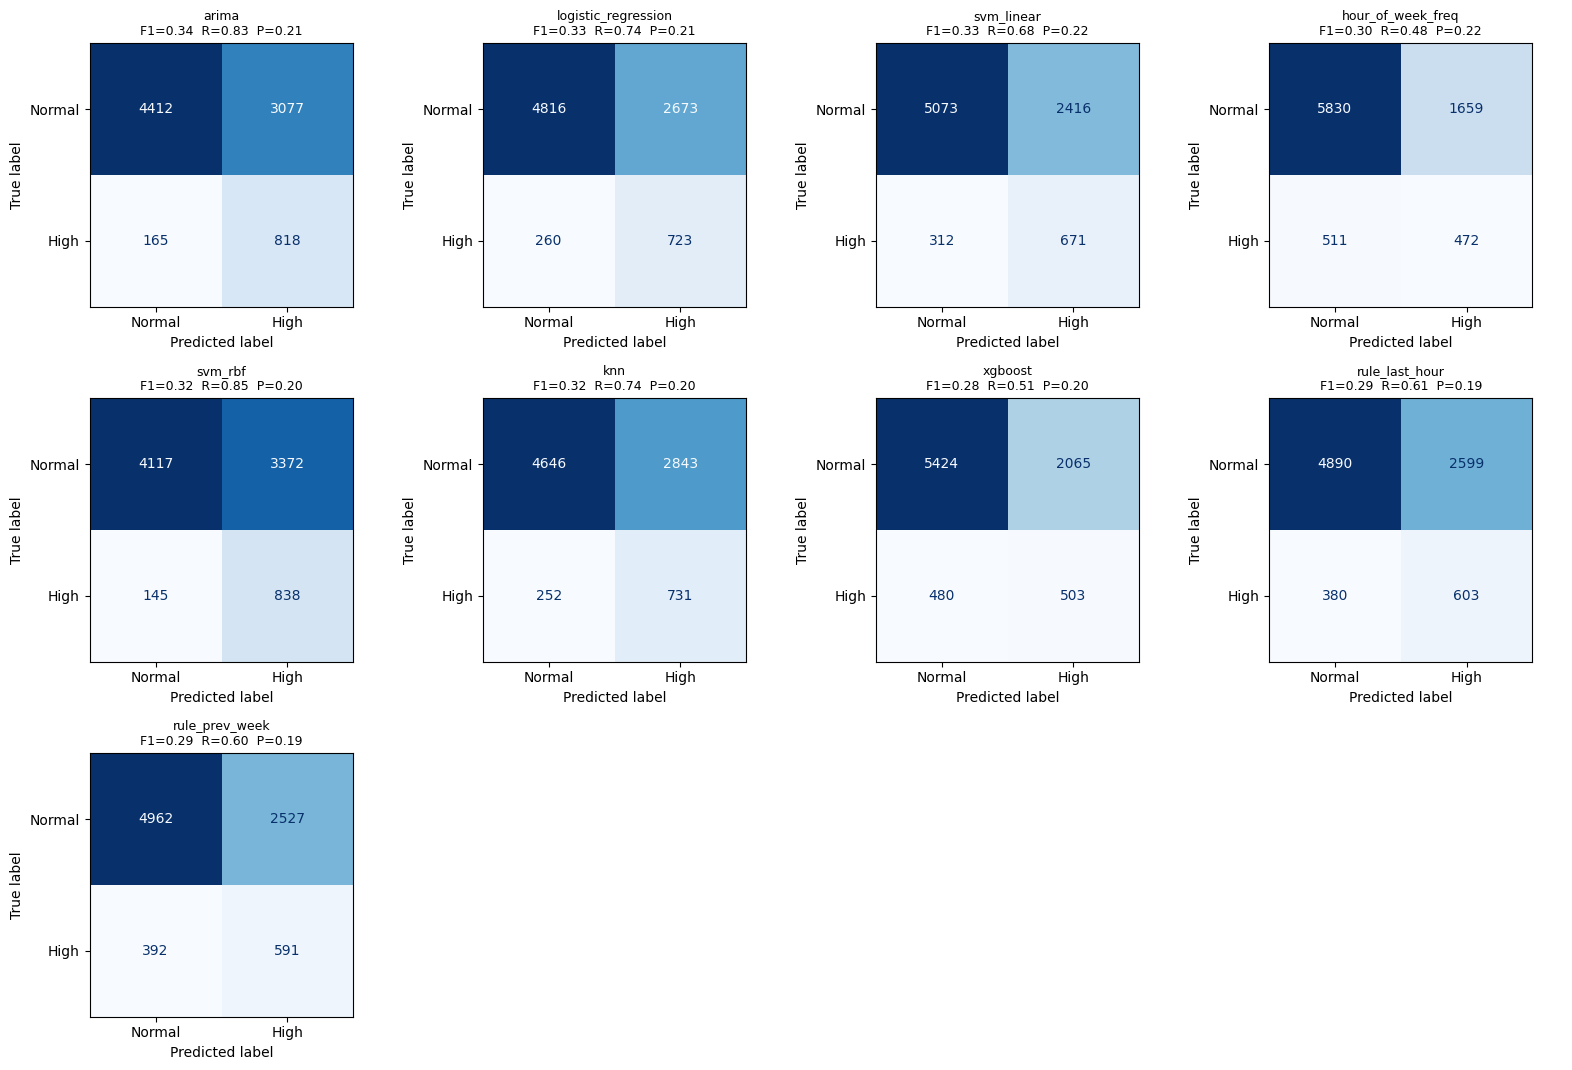

In [128]:
# Confusion matrices on test at the validation-tuned cutoff
names = list(test_pr.index[::-1])
cols = 4
rows_ = int(np.ceil(len(names) / cols))
fig, axes = plt.subplots(rows_, cols, figsize=(4 * cols, 3.6 * rows_))
for ax, name in zip(axes.ravel(), names):
    r = res[(res["model"] == name) & (res["split"] == "test") & (res["cutoff"] != "default")].iloc[0]
    ConfusionMatrixDisplay(np.array([[r.tn, r.fp], [r.fn, r.tp]]), display_labels=["Normal", "High"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}\nF1={r.f1:.2f}  R={r.recall:.2f}  P={r.precision:.2f}", fontsize=9)
for ax in axes.ravel()[len(names):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Feature importance

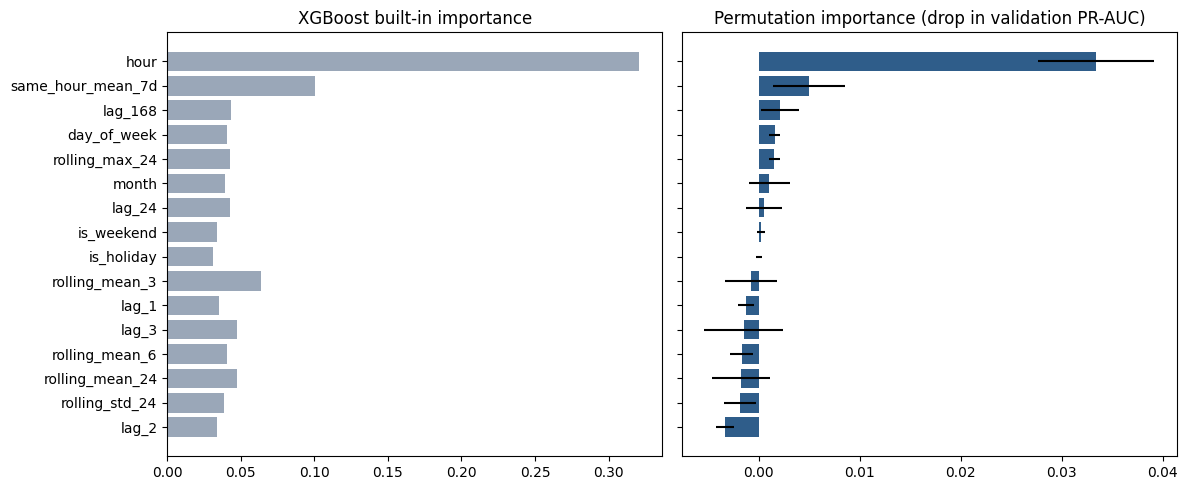

,xgb_gain,perm_drop_pr_auc,perm_std
hour,0.3203,0.0334,0.0057
same_hour_mean_7d,0.1008,0.0050,0.0036
lag_168,0.0431,0.0021,0.0019
day_of_week,0.0404,0.0016,0.0006
rolling_max_24,0.0426,0.0016,0.0006
month,0.0389,0.0011,0.0020
lag_24,0.0424,0.0006,0.0018
is_weekend,0.0337,0.0003,0.0004
is_holiday,0.0314,0.0001,0.0003
rolling_mean_3,0.0638,-0.0007,0.0026


In [129]:
perm = permutation_importance(xgb, X_va[TREE_FEATURES], y_va, scoring="average_precision",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"xgb_gain": xgb.feature_importances_,
                    "perm_drop_pr_auc": perm.importances_mean,
                    "perm_std": perm.importances_std}, index=TREE_FEATURES).sort_values("perm_drop_pr_auc")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].barh(imp.index, imp["xgb_gain"], color="#9aa7b8"); axes[0].set_title("XGBoost built-in importance")
axes[1].barh(imp.index, imp["perm_drop_pr_auc"], xerr=imp["perm_std"], color="#2f5d8a")
axes[1].set_title("Permutation importance (drop in validation PR-AUC)")
plt.tight_layout(); plt.show()
imp.sort_values("perm_drop_pr_auc", ascending=False).round(4)

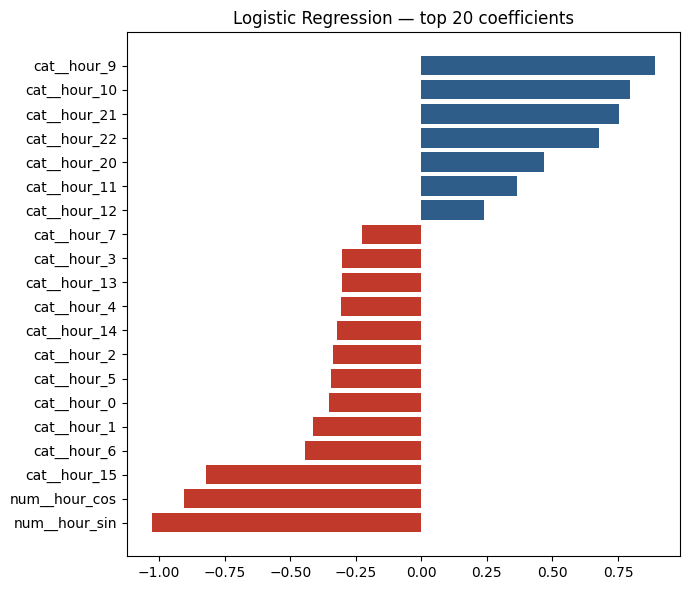

In [130]:
# Logistic Regression coefficients (standardized numeric features + one-hot hour / weekday)
feat_names = lr.named_steps["pre"].get_feature_names_out()
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=feat_names)
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:20]).sort_values()
plt.figure(figsize=(7, 6)); plt.barh(top.index, top.values, color=np.where(top > 0, "#2f5d8a", "#c0392b"))
plt.title("Logistic Regression — top 20 coefficients"); plt.tight_layout(); plt.show()

## 7. Export for 1.5 (tuning) and 1.6 (evaluation)

In [131]:
PRED["validation"].to_csv("predictions_validation.csv", index=False)
PRED["test"].to_csv("predictions_test.csv", index=False)
res.to_csv("model_results.csv", index=False)
with open("best_params.json", "w") as f:
    json.dump(BEST_PARAMS, f, indent=2, default=str)
print("Saved: predictions_validation.csv, predictions_test.csv, model_results.csv, best_params.json")
print("Score columns:", [c for c in PRED["test"].columns if c.startswith("score_")])

Saved: predictions_validation.csv, predictions_test.csv, model_results.csv, best_params.json
Score columns: ['score_rule_prev_week', 'score_rule_last_hour', 'score_hour_of_week_freq', 'score_arima', 'score_logistic_regression', 'score_knn', 'score_svm_linear', 'score_svm_rbf', 'score_xgboost']


In [132]:
t = table("test")
best = t.index[0]
lines = [f"1.4 results (test 2017, positive rate {y_te.mean():.1%}, no-skill PR-AUC {y_te.mean():.3f})"]
for m in t.index:
    lines.append(f"- {m:<20} PR-AUC {t.loc[m, ('pr_auc', '')]:.3f} | val-tuned cutoff: "
                 f"R {t.loc[m, ('recall', 'val-tuned (prelim.)')]:.2f} "
                 f"P {t.loc[m, ('precision', 'val-tuned (prelim.)')]:.2f} "
                 f"F1 {t.loc[m, ('f1', 'val-tuned (prelim.)')]:.2f}")
lines.append(f"Best by PR-AUC: {best}.")
print("\n".join(lines))

1.4 results (test 2017, positive rate 11.6%, no-skill PR-AUC 0.116)
- arima                PR-AUC 0.236 | val-tuned cutoff: R 0.83 P 0.21 F1 0.34
- logistic_regression  PR-AUC 0.235 | val-tuned cutoff: R 0.74 P 0.21 F1 0.33
- svm_linear           PR-AUC 0.233 | val-tuned cutoff: R 0.68 P 0.22 F1 0.33
- hour_of_week_freq    PR-AUC 0.218 | val-tuned cutoff: R 0.48 P 0.22 F1 0.30
- svm_rbf              PR-AUC 0.215 | val-tuned cutoff: R 0.85 P 0.20 F1 0.32
- knn                  PR-AUC 0.215 | val-tuned cutoff: R 0.74 P 0.20 F1 0.32
- xgboost              PR-AUC 0.208 | val-tuned cutoff: R 0.51 P 0.20 F1 0.28
- rule_last_hour       PR-AUC 0.181 | val-tuned cutoff: R 0.61 P 0.19 F1 0.29
- rule_prev_week       PR-AUC 0.181 | val-tuned cutoff: R 0.60 P 0.19 F1 0.29
Best by PR-AUC: arima.


In [133]:
## 7b. Hourly probabilities for all models (validation + test) in one CSV

# prob_rule: hour_of_week_freq is the only rule baseline that outputs a real probability
#            (rule_prev_week / rule_last_hour are 0/1, so a cutoff can't be tuned on them).
# prob_svm : None = pick linear vs. RBF by validation PR-AUC; or set "svm_linear" / "svm_rbf".
RULE_EXPORT = "hour_of_week_freq"
SVM_EXPORT  = None

if SVM_EXPORT is None:
    SVM_EXPORT = max(("svm_linear", "svm_rbf"),
                     key=lambda m: average_precision_score(y_va, SCORES[m][0]))
print("SVM variant exported as prob_svm:", SVM_EXPORT)

EXPORT_MAP = {
    "prob_rule":  RULE_EXPORT,
    "prob_arima": "arima",
    "prob_lr":    "logistic_regression",
    "prob_knn":   "knn",
    "prob_svm":   SVM_EXPORT,
    "prob_xgb":   "xgboost",
}
PROB_COLS = list(EXPORT_MAP)

def build_split(split, k):   # k = 0 -> validation scores, 1 -> test scores
    out = PRED[split][["datetime", "y"]].rename(columns={"y": "y_true"}).copy()
    out.insert(1, "split", split)
    for col, name in EXPORT_MAP.items():
        out[col] = np.asarray(SCORES[name][k], dtype=float)
    return out

probs = pd.concat([build_split("validation", 0), build_split("test", 1)], ignore_index=True)

# Integrity checks
assert len(probs) == len(X_va) + len(X_te)
assert probs["datetime"].is_unique and probs["datetime"].is_monotonic_increasing
assert probs[PROB_COLS + ["y_true"]].notna().all().all(), "NaN found in probabilities"
assert probs[PROB_COLS].min().min() >= 0 and probs[PROB_COLS].max().max() <= 1, "prob outside [0, 1]"
assert set(probs["y_true"].unique()) <= {0, 1}

probs.to_csv("model_probabilities.csv", index=False)
print(f"Saved model_probabilities.csv: {probs.shape[0]:,} rows × {probs.shape[1]} columns")
print(probs.groupby("split", sort=False).size().to_string())

# Round-trip check: recompute PR-AUC from the saved file
chk = pd.read_csv("model_probabilities.csv", parse_dates=["datetime"])
pr = pd.DataFrame({
    s: {c: average_precision_score(g["y_true"], g[c]) for c in PROB_COLS}
    for s, g in chk.groupby("split")
}).T.round(3)
pr["no_skill"] = chk.groupby("split")["y_true"].mean().round(3)
print("\nPR-AUC recomputed from the CSV (should match the comparison tables):")
display(pr)

chk.head()

SVM variant exported as prob_svm: svm_linear
Saved model_probabilities.csv: 16,968 rows × 9 columns
split
validation    8496
test          8472

PR-AUC recomputed from the CSV (should match the comparison tables):


,prob_rule,prob_arima,prob_lr,prob_knn,prob_svm,prob_xgb,no_skill
test,0.218,0.236,0.235,0.215,0.233,0.208,0.116
validation,0.148,0.173,0.170,0.153,0.166,0.137,0.074


,datetime,split,y_true,prob_rule,prob_arima,prob_lr,prob_knn,prob_svm,prob_xgb
0,2016-01-01 00:00:00,validation,0,0.0,0.001297,0.046200,0.026724,0.007074,0.000412
1,2016-01-01 01:00:00,validation,0,0.0,0.000713,0.030829,0.027552,0.005846,0.000566
2,2016-01-01 02:00:00,validation,0,0.0,0.000451,0.024989,0.012644,0.005735,0.000492
3,2016-01-01 03:00:00,validation,0,0.0,0.000353,0.025661,0.026818,0.005839,0.002672
4,2016-01-01 04:00:00,validation,0,0.0,0.000293,0.021793,0.017872,0.005133,0.001956


In [134]:
chk = pd.read_csv("model_probabilities.csv", parse_dates=["datetime"])
print("Total rows:", len(chk))
print(chk.groupby("split").agg(rows=("datetime", "size"),
                               start=("datetime", "min"),
                               end=("datetime", "max")))
display(chk.head(24))   # first full day
display(chk.tail(24))   # last day of 2017

Total rows: 16968
            rows      start                 end
split                                          
test        8472 2017-01-01 2017-12-30 23:00:00
validation  8496 2016-01-01 2016-12-30 23:00:00


,datetime,split,y_true,prob_rule,prob_arima,prob_lr,prob_knn,prob_svm,prob_xgb
0,2016-01-01 00:00:00,validation,0,0.00,0.001297,0.046200,0.026724,0.007074,0.000412
1,2016-01-01 01:00:00,validation,0,0.00,0.000713,0.030829,0.027552,0.005846,0.000566
2,2016-01-01 02:00:00,validation,0,0.00,0.000451,0.024989,0.012644,0.005735,0.000492
3,2016-01-01 03:00:00,validation,0,0.00,0.000353,0.025661,0.026818,0.005839,0.002672
4,2016-01-01 04:00:00,validation,0,0.00,0.000293,0.021793,0.017872,0.005133,0.001956
5,2016-01-01 05:00:00,validation,0,0.00,0.000329,0.025379,0.013062,0.005896,0.001581
6,2016-01-01 06:00:00,validation,0,0.00,0.000622,0.029522,0.013300,0.006409,0.003437
7,2016-01-01 07:00:00,validation,0,0.01,0.001717,0.058880,0.017075,0.008421,0.021943
8,2016-01-01 08:00:00,validation,0,0.01,0.007962,0.120037,0.025641,0.012742,0.325135
9,2016-01-01 09:00:00,validation,0,0.04,0.024534,0.404045,0.034645,0.036092,0.397164


,datetime,split,y_true,prob_rule,prob_arima,prob_lr,prob_knn,prob_svm,prob_xgb
16944,2017-12-30 00:00:00,test,0,0.01,0.003747,0.064358,0.028778,0.008987,0.011301
16945,2017-12-30 01:00:00,test,0,0.00,0.001696,0.034407,0.019783,0.006608,0.003225
16946,2017-12-30 02:00:00,test,0,0.00,0.001482,0.027569,0.009034,0.006034,0.002990
16947,2017-12-30 03:00:00,test,0,0.00,0.001395,0.029037,0.009929,0.006385,0.004081
16948,2017-12-30 04:00:00,test,0,0.00,0.001088,0.036492,0.014756,0.008137,0.003049
16949,2017-12-30 05:00:00,test,0,0.00,0.000838,0.032799,0.004757,0.007346,0.002257
16950,2017-12-30 06:00:00,test,0,0.00,0.001151,0.030301,0.004469,0.006503,0.002372
16951,2017-12-30 07:00:00,test,0,0.00,0.004219,0.057393,0.005022,0.008578,0.021508
16952,2017-12-30 08:00:00,test,0,0.00,0.018219,0.147018,0.016579,0.013697,0.083633
16953,2017-12-30 09:00:00,test,0,0.01,0.058715,0.506601,0.042204,0.048344,0.539400


#1.5

In [135]:
import json
import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_recall_curve,
    f1_score,
    precision_score,
    recall_score,
    average_precision_score,
)

# 1. Load exported hourly probabilities
probs = pd.read_csv("model_probabilities.csv", parse_dates=["datetime"])
prob_cols = [c for c in probs.columns if c.startswith("prob_")]

# Strictly isolate validation and test splits
val_df = probs[probs["split"] == "validation"].copy()
test_df = probs[probs["split"] == "test"].copy()

y_val = val_df["y_true"].to_numpy()
y_test = test_df["y_true"].to_numpy()

# 2. Tune probability cutoff per model using ONLY validation rows
tuned_cutoffs = {}
tuning_summary = []

for col in prob_cols:
    val_scores = val_df[col].to_numpy()
    precisions, recalls, thresholds = precision_recall_curve(y_val, val_scores)

    # precision_recall_curve returns n+1 precisions/recalls for n thresholds
    p = precisions[:-1]
    r = recalls[:-1]

    # Maximize F1-score on validation set
    f1_scores = np.where((p + r) > 0, 2 * (p * r) / (p + r), 0.0)
    best_idx = int(np.argmax(f1_scores))
    best_cutoff = float(thresholds[best_idx])

    # Store using both the column name (e.g., "prob_xgb") and short model key ("xgb")
    # so downstream evaluation scripts match regardless of key convention
    tuned_cutoffs[col] = round(best_cutoff, 6)

    # Evaluate locked cutoff on validation & unchanged on test
    val_pred = (val_scores >= best_cutoff).astype(int)
    test_scores = test_df[col].to_numpy()
    test_pred = (test_scores >= best_cutoff).astype(int)

    tuning_summary.append({
        "model": col,
        "cutoff": round(best_cutoff, 4),
        "val_pr_auc": round(average_precision_score(y_val, val_scores), 3),
        "val_f1": round(f1_score(y_val, val_pred, zero_division=0), 3),
        "test_pr_auc": round(average_precision_score(y_test, test_scores), 3),
        "test_recall": round(recall_score(y_test, test_pred, zero_division=0), 3),
        "test_precision": round(precision_score(y_test, test_pred, zero_division=0), 3),
        "test_f1": round(f1_score(y_test, test_pred, zero_division=0), 3),
    })

# 3. Export tuned_cutoffs.json for Section 1.6
with open("tuned_cutoffs.json", "w") as f:
    json.dump(tuned_cutoffs, f, indent=2)

print("Saved tuned_cutoffs.json:")
print(json.dumps(tuned_cutoffs, indent=2))

print("\nValidation-Tuned Cutoffs Applied Unchanged to Test Set:")
summary_df = pd.DataFrame(tuning_summary).sort_values("test_pr_auc", ascending=False)
display(summary_df)

Saved tuned_cutoffs.json:
{
  "prob_rule": 0.087379,
  "prob_arima": 0.069451,
  "prob_lr": 0.64802,
  "prob_knn": 0.0763,
  "prob_svm": 0.077119,
  "prob_xgb": 0.573536
}

Validation-Tuned Cutoffs Applied Unchanged to Test Set:


/tmp/ipykernel_3190/1050381564.py:36: RuntimeWarning: invalid value encountered in divide
  f1_scores = np.where((p + r) > 0, 2 * (p * r) / (p + r), 0.0)
/tmp/ipykernel_3190/1050381564.py:36: RuntimeWarning: invalid value encountered in divide
  f1_scores = np.where((p + r) > 0, 2 * (p * r) / (p + r), 0.0)
/tmp/ipykernel_3190/1050381564.py:36: RuntimeWarning: invalid value encountered in divide
  f1_scores = np.where((p + r) > 0, 2 * (p * r) / (p + r), 0.0)
/tmp/ipykernel_3190/1050381564.py:36: RuntimeWarning: invalid value encountered in divide
  f1_scores = np.where((p + r) > 0, 2 * (p * r) / (p + r), 0.0)
/tmp/ipykernel_3190/1050381564.py:36: RuntimeWarning: invalid value encountered in divide
  f1_scores = np.where((p + r) > 0, 2 * (p * r) / (p + r), 0.0)


,model,cutoff,val_pr_auc,val_f1,test_pr_auc,test_recall,test_precision,test_f1
1,prob_arima,0.0695,0.173,0.255,0.236,0.832,0.210,0.335
2,prob_lr,0.6480,0.170,0.259,0.235,0.736,0.213,0.330
4,prob_svm,0.0771,0.166,0.255,0.233,0.683,0.217,0.330
0,prob_rule,0.0874,0.148,0.242,0.218,0.480,0.221,0.303
3,prob_knn,0.0763,0.153,0.240,0.215,0.744,0.205,0.321
5,prob_xgb,0.5735,0.137,0.221,0.208,0.512,0.196,0.283


# 1.6 Evaluation, Comparison & Interpretation
**Inputs** (exported by the *1.4 Baselines and Model Development* section above, optionally updated by 1.5 tuning):


| File | Required | Content |
|---|---|---|
| `predictions_validation.csv`, `predictions_test.csv` | yes | `datetime, arrivals, y, score_<model>…` |
| `feature_importance_xgb.csv`, `lr_coefficients.csv` | for Section 6 | XGBoost / LR interpretation |
| `tuned_cutoffs.json` | optional (from 1.5) | `{"<model>": cutoff}` chosen in 1.5 on **validation only**. Models not listed fall back to the F1-maximizing cutoff on validation. |
| `tuned_probabilities.csv` | optional (from 1.5) | Same layout as `model_probabilities.csv`: `datetime, split, y_true, prob_<name>…` with **both** validation and test rows; each `prob_<name>` column becomes model `<name>` (e.g. `prob_xgb_smote` → `xgb_smote`). |
| `predictions_*_tuned.csv` | optional | Alternative format: extra `score_<name>` columns per split, merged on `datetime`. |

**Rules.** Every cutoff is chosen on 2016 validation and applied unchanged to 2017 test. Test is used only for reporting.

**Outputs:** `final_comparison.csv`, `figures/*.png` (ready for the report and slides), and an auto-generated findings summary.
**加粗文字**

In [136]:


import os, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (average_precision_score, precision_recall_curve, precision_score,
                             recall_score, f1_score, confusion_matrix)

pd.set_option("display.width", 160)
N_BOOT, SEED = 500, 42
ALERT_BUDGETS = [3, 6]          # alerts per day for operating-point comparison
REFERENCE = "hour_of_week_freq" # strongest no-learning baseline
os.makedirs("figures", exist_ok=True)

def load(split):
    df = pd.read_csv(f"predictions_{split}.csv", parse_dates=["datetime"])
    for extra in sorted(glob.glob(f"predictions_{split}_*tuned*.csv")):
        add = pd.read_csv(extra, parse_dates=["datetime"])
        new = [c for c in add.columns if c.startswith("score_") and c not in df.columns]
        df = df.merge(add[["datetime"] + new], on="datetime", how="left", validate="1:1")
        print(f"merged {extra}: {new}")
    if os.path.exists("tuned_probabilities.csv"):
        tp = pd.read_csv("tuned_probabilities.csv", parse_dates=["datetime"])
        tp = tp[tp["split"] == split]
        ren = {c: "score_" + c[len("prob_"):] for c in tp.columns if c.startswith("prob_")}
        ren = {k: v for k, v in ren.items() if v not in df.columns}
        merged = df.merge(tp[["datetime"] + list(ren)].rename(columns=ren), on="datetime", how="left", validate="1:1")
        missing = merged[list(ren.values())].isna().any()
        assert not missing.any(), f"tuned_probabilities.csv is missing {split} rows for {list(missing[missing].index)}"
        if "y_true" in tp:
            chk = df[["datetime", "y"]].merge(tp[["datetime", "y_true"]], on="datetime")
            assert (chk["y"] == chk["y_true"]).all(), "tuned_probabilities.csv labels do not match"
        df = merged
        print(f"merged tuned_probabilities.csv ({split}): {list(ren.values())}")
    return df

va, te = load("validation"), load("test")
MODELS = [c[len("score_"):] for c in te.columns if c.startswith("score_")]
assert not va[[f"score_{m}" for m in MODELS]].isna().any().any(), "validation scores contain NaN"
assert not te[[f"score_{m}" for m in MODELS]].isna().any().any(), "test scores contain NaN"

y_va, y_te = va["y"].to_numpy(), te["y"].to_numpy()
HD_THRESHOLD = te.loc[te["y"] == 0, "arrivals"].max()
print(f"Models: {MODELS}")
print(f"Threshold: arrivals > {HD_THRESHOLD:g} | positive rate validation {y_va.mean():.1%}, test {y_te.mean():.1%}")
def f1_cutoff(y, s):
    p, r, t = precision_recall_curve(y, s)
    f = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[np.nanargmax(f)])

def budget_cutoff(s, alerts_per_day):
    # Cutoff that produces the given average alerts/day on validation
    return float(np.quantile(s, 1 - alerts_per_day / 24))

if os.path.exists("tuned_cutoffs.json"):
    CUTOFFS = {k: float(v) for k, v in json.load(open("tuned_cutoffs.json")).items() if k in MODELS}
    print("Using cutoffs from tuned_cutoffs.json for:", list(CUTOFFS))
    unknown = set(json.load(open("tuned_cutoffs.json"))) - set(MODELS)
    if unknown: print("WARNING: cutoffs given for unknown model names (ignored):", sorted(unknown))
else:
    CUTOFFS = {}
for m in MODELS:
    CUTOFFS.setdefault(m, f1_cutoff(y_va, va[f"score_{m}"].to_numpy()))

def metrics(y, s, cut):
    p = (s >= cut).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return {"recall": recall_score(y, p, zero_division=0), "precision": precision_score(y, p, zero_division=0),
            "f1": f1_score(y, p, zero_division=0), "alerts_per_day": p.mean() * 24,
            "missed_per_week": fn / (len(y) / 168), "false_alarms_per_day": fp / (len(y) / 24),
            "tp": tp, "fp": fp, "fn": fn, "tn": tn}


Models: ['rule_prev_week', 'rule_last_hour', 'hour_of_week_freq', 'arima', 'logistic_regression', 'knn', 'svm_linear', 'svm_rbf', 'xgboost']
Threshold: arrivals > 8 | positive rate validation 7.4%, test 11.6%
Using cutoffs from tuned_cutoffs.json for: []


## 1. Uncertainty: block bootstrap by day

Hourly errors are autocorrelated, so we resample **whole days** (not hours) from the test year. For each model: PR-AUC with a 95% interval, and the **paired** difference vs. the reference baseline (`hour_of_week_freq`) computed on the same resampled days.


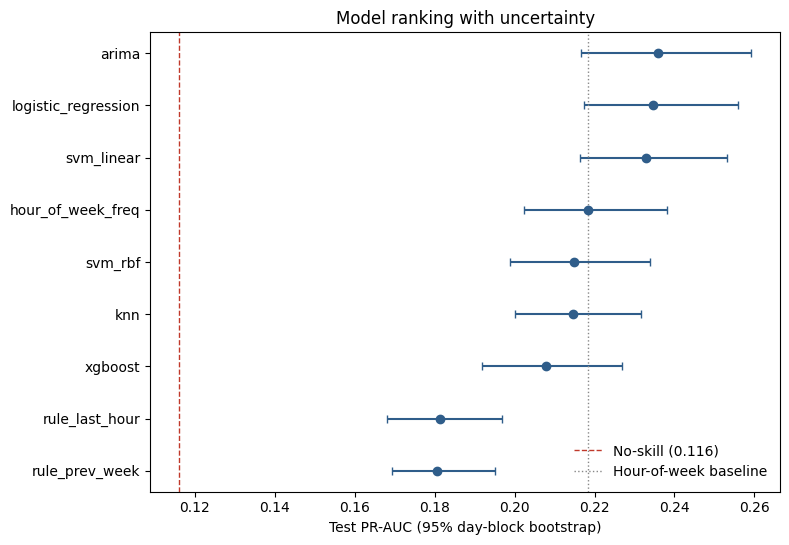

In [137]:
rng = np.random.default_rng(SEED)
day_id = te["datetime"].dt.normalize().factorize()[0]
day_rows = [np.flatnonzero(day_id == d) for d in range(day_id.max() + 1)]
S_te = {m: te[f"score_{m}"].to_numpy() for m in MODELS}

boot = {m: [] for m in MODELS}
for _ in range(N_BOOT):
    idx = np.concatenate([day_rows[d] for d in rng.integers(0, len(day_rows), len(day_rows))])
    yb = y_te[idx]
    for m in MODELS:
        boot[m].append(average_precision_score(yb, S_te[m][idx]))
boot = pd.DataFrame(boot)

rows = []
for m in MODELS:
    pr = average_precision_score(y_te, S_te[m])
    met = metrics(y_te, S_te[m], CUTOFFS[m])
    row = {"model": m, "pr_auc": pr,
           "pr_auc_lo": boot[m].quantile(0.025), "pr_auc_hi": boot[m].quantile(0.975),
           "lift_vs_no_skill": pr / y_te.mean(),
           "val_pr_auc": average_precision_score(y_va, va[f"score_{m}"]),
           "cutoff": CUTOFFS[m], **met}
    if REFERENCE in MODELS and m != REFERENCE:
        d = boot[m] - boot[REFERENCE]
        row.update({"delta_vs_ref": pr - average_precision_score(y_te, S_te[REFERENCE]),
                    "delta_lo": d.quantile(0.025), "delta_hi": d.quantile(0.975), "p_better": (d > 0).mean()})
    rows.append(row)

final = pd.DataFrame(rows).set_index("model").sort_values("pr_auc", ascending=False)
final.to_csv("final_comparison.csv")
show = ["pr_auc", "pr_auc_lo", "pr_auc_hi", "lift_vs_no_skill", "delta_vs_ref", "delta_lo", "delta_hi", "p_better",
        "recall", "precision", "f1", "alerts_per_day", "missed_per_week", "false_alarms_per_day"]
final[[c for c in show if c in final]].round(3)
fig, ax = plt.subplots(figsize=(8, 0.45 * len(final) + 1.5))
order = final.sort_values("pr_auc")
ax.errorbar(order["pr_auc"], order.index, xerr=[order["pr_auc"] - order["pr_auc_lo"], order["pr_auc_hi"] - order["pr_auc"]],
            fmt="o", color="#2f5d8a", capsize=3)
ax.axvline(y_te.mean(), color="#c0392b", ls="--", lw=1, label=f"No-skill ({y_te.mean():.3f})")
if REFERENCE in final.index:
    ax.axvline(final.loc[REFERENCE, "pr_auc"], color="#888", ls=":", lw=1, label="Hour-of-week baseline")
ax.set_xlabel("Test PR-AUC (95% day-block bootstrap)"); ax.legend(frameon=False, loc="lower right")
ax.set_title("Model ranking with uncertainty")
plt.tight_layout(); plt.savefig("figures/01_pr_auc_ranking.png", dpi=200); plt.show()

## 2. Operating points: what does an ED manager get for a fixed alert budget?

A staffing alert is only useful if it is not raised too often. Two views:

* **Equal alert rate (ranking quality):** each model raises exactly *b* alerts/day on test (its top-scored hours). This compares models fairly at the same workload; it is an evaluation metric, not a tuned cutoff.
* **Deployable cutoff:** the cutoff giving *b* alerts/day on 2016 is applied to 2017. Because 2017 volume is higher, a model whose scores follow the arrival level raises more than *b* alerts/day on test — check `actual_alerts_per_day` before comparing recall.



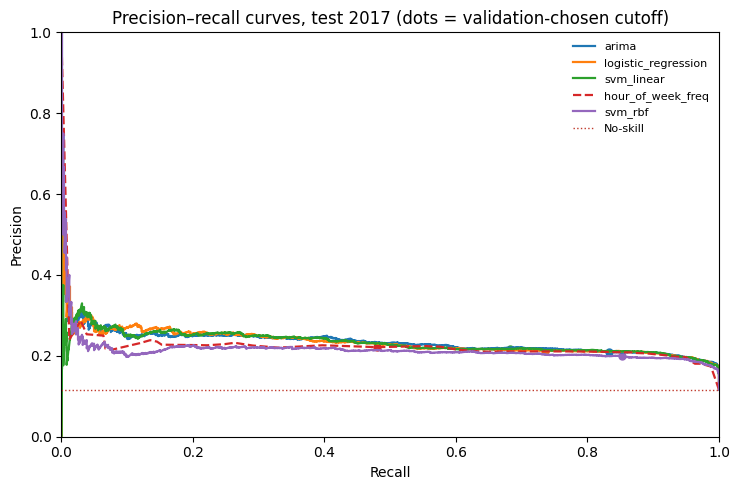

In [138]:
rows = []
for b in ALERT_BUDGETS:
    k = int(round(len(y_te) * b / 24))
    for m in MODELS:
        top = np.argsort(-S_te[m], kind="stable")[:k]          # equal alert rate on test
        cut = budget_cutoff(va[f"score_{m}"].to_numpy(), b)    # deployable: cutoff from validation
        met = metrics(y_te, S_te[m], cut)
        rows.append({"budget_alerts_per_day": b, "model": m,
                     "recall": y_te[top].sum() / y_te.sum(), "precision": y_te[top].mean(),
                     "deploy_recall": met["recall"], "deploy_precision": met["precision"],
                     "actual_alerts_per_day": met["alerts_per_day"]})
budget = pd.DataFrame(rows)
budget_tbl = budget.pivot(index="model", columns="budget_alerts_per_day",
                          values=["recall", "precision", "deploy_recall", "actual_alerts_per_day"]).round(3)
budget_tbl.sort_values(("recall", ALERT_BUDGETS[-1]), ascending=False)
top = list(final.index[:5]) + ([REFERENCE] if REFERENCE not in final.index[:5] and REFERENCE in MODELS else [])
fig, ax = plt.subplots(figsize=(7.5, 5))
for m in top:
    p, r, _ = precision_recall_curve(y_te, S_te[m])
    ax.plot(r, p, lw=1.6, ls="--" if m == REFERENCE else "-", label=m)
    met = metrics(y_te, S_te[m], CUTOFFS[m])
    ax.scatter(met["recall"], met["precision"], s=25)
ax.axhline(y_te.mean(), color="#c0392b", ls=":", lw=1, label="No-skill")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title("Precision–recall curves, test 2017 (dots = validation-chosen cutoff)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig("figures/02_pr_curves.png", dpi=200); plt.show()

## 3. Confusion matrices at the chosen cutoff

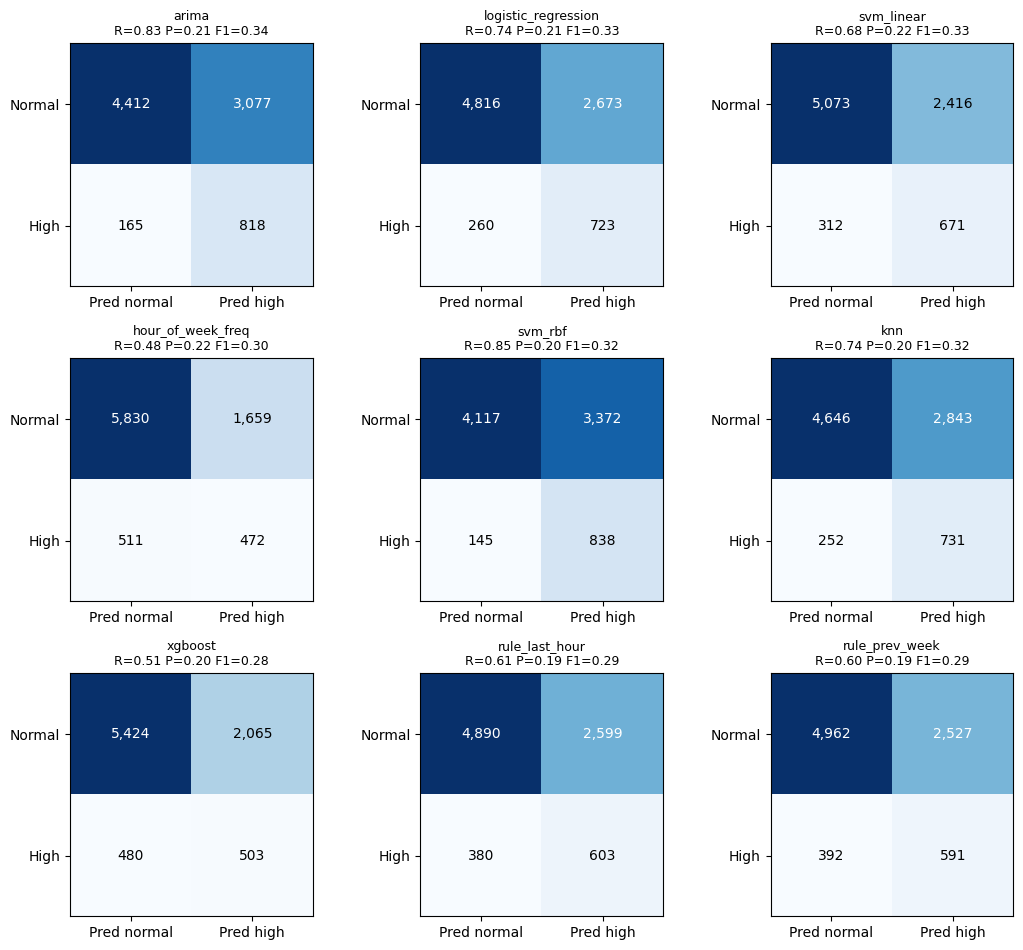

In [139]:
names = list(final.index)
cols = 3; rws = int(np.ceil(len(names) / cols))
fig, axes = plt.subplots(rws, cols, figsize=(3.6 * cols, 3.2 * rws))
for ax, m in zip(axes.ravel(), names):
    r = final.loc[m]
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{int(v):,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Pred normal", "Pred high"]); ax.set_yticks([0, 1], ["Normal", "High"])
    ax.set_title(f"{m}\nR={r.recall:.2f} P={r.precision:.2f} F1={r.f1:.2f}", fontsize=9)
for ax in axes.ravel()[len(names):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig("figures/03_confusion_matrices.png", dpi=200); plt.show()

## 4. Error analysis for the best model

* When does it miss? Recall and false alarms by hour of day and by month.
* Does it catch the **large** surges? Recall by how far arrivals exceed the threshold.

/tmp/ipykernel_3190/2169184960.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "recall": g.apply(lambda d: d["pred"][d["y"] == 1].mean() if d["y"].sum() else np.nan),
/tmp/ipykernel_3190/2169184960.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "false_alarms_per_day": g.apply(lambda d: ((d["pred"] == 1) & (d["y"] == 0)).sum()) / (len(ea) / 24)})
/tmp/ipykernel_3190/2169184960.py:8: DeprecationWarni

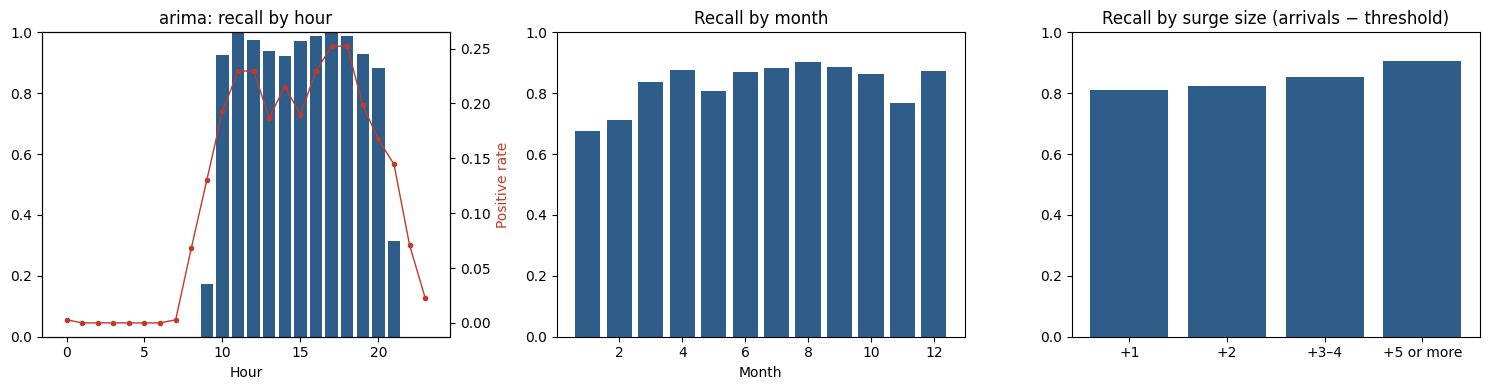

,recall,hours
excess,,
+1,0.811,423
+2,0.824,245
+3–4,0.855,241
+5 or more,0.905,74


In [140]:
BEST = final.index[0]
s = S_te[BEST]; pred = (s >= CUTOFFS[BEST]).astype(int)
ea = te.assign(pred=pred, hour=te["datetime"].dt.hour, month=te["datetime"].dt.month)

def by(col):
    g = ea.groupby(col)
    return pd.DataFrame({"positive_rate": g["y"].mean(),
                         "recall": g.apply(lambda d: d["pred"][d["y"] == 1].mean() if d["y"].sum() else np.nan),
                         "false_alarms_per_day": g.apply(lambda d: ((d["pred"] == 1) & (d["y"] == 0)).sum()) / (len(ea) / 24)})

hr, mo = by("hour"), by("month")
pos = ea[ea["y"] == 1].copy()
pos["excess"] = pd.cut(pos["arrivals"] - HD_THRESHOLD, [0, 1, 2, 4, np.inf], labels=["+1", "+2", "+3–4", "+5 or more"])
surge = pos.groupby("excess", observed=True)["pred"].agg(["mean", "size"]).rename(columns={"mean": "recall", "size": "hours"})

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(hr.index, hr["recall"], color="#2f5d8a"); axes[0].set_title(f"{BEST}: recall by hour"); axes[0].set_xlabel("Hour")
ax2 = axes[0].twinx(); ax2.plot(hr.index, hr["positive_rate"], color="#c0392b", marker=".", lw=1); ax2.set_ylabel("Positive rate", color="#c0392b")
axes[1].bar(mo.index, mo["recall"], color="#2f5d8a"); axes[1].set_title("Recall by month"); axes[1].set_xlabel("Month")
axes[2].bar(surge.index.astype(str), surge["recall"], color="#2f5d8a"); axes[2].set_title("Recall by surge size (arrivals − threshold)")
for ax in axes: ax.set_ylim(0, 1)
plt.tight_layout(); plt.savefig("figures/04_error_analysis.png", dpi=200); plt.show()
display(surge.round(3))

## 5. Stability: validation (2016) vs. test (2017)

A model whose ranking flips between years is not reliable. Test positive rate is higher than validation (volume growth), so PR-AUC is also shown relative to each year's no-skill level.


In [141]:
stab = pd.DataFrame({"val_pr_auc": final["val_pr_auc"], "test_pr_auc": final["pr_auc"],
                     "val_lift": final["val_pr_auc"] / y_va.mean(), "test_lift": final["pr_auc"] / y_te.mean()})
stab["val_rank"] = stab["val_pr_auc"].rank(ascending=False).astype(int)
stab["test_rank"] = stab["test_pr_auc"].rank(ascending=False).astype(int)
stab.round(3)

,val_pr_auc,test_pr_auc,val_lift,test_lift,val_rank,test_rank
model,,,,,,
arima,0.173,0.236,2.333,2.034,1,1
logistic_regression,0.170,0.235,2.301,2.022,2,2
svm_linear,0.166,0.233,2.240,2.007,3,3
hour_of_week_freq,0.148,0.218,1.996,1.882,5,4
svm_rbf,0.142,0.215,1.915,1.851,6,5
knn,0.153,0.215,2.073,1.850,4,6
xgboost,0.137,0.208,1.845,1.792,7,7
rule_last_hour,0.122,0.181,1.649,1.563,9,8
rule_prev_week,0.128,0.181,1.735,1.556,8,9


## 6. Feature interpretation

Features are grouped into families to answer *where the signal comes from*: time of day / calendar, the same hour in previous days/weeks (weekly pattern), and the last few hours (short-term momentum).



In [142]:
FAMILY = {"hour": "Time of day", "hour_sin": "Time of day", "hour_cos": "Time of day",
          "day_of_week": "Calendar", "day_of_week_sin": "Calendar", "day_of_week_cos": "Calendar",
          "month": "Calendar", "month_sin": "Calendar", "month_cos": "Calendar",
          "is_weekend": "Calendar", "is_holiday": "Calendar",
          "lag_24": "Recurring pattern (day/week)", "lag_168": "Recurring pattern (day/week)",
          "same_hour_mean_7d": "Recurring pattern (day/week)",
          "lag_1": "Recent hours", "lag_2": "Recent hours", "lag_3": "Recent hours",
          "rolling_mean_3": "Recent hours", "rolling_mean_6": "Recent hours",
          "rolling_mean_24": "Last 24 h level", "rolling_std_24": "Last 24 h level", "rolling_max_24": "Last 24 h level"}
fam = lambda f: FAMILY.get(f, "Time of day" if f.startswith("cat__hour") else
                              "Calendar" if f.startswith("cat__day_of_week") else "Other")

if os.path.exists("feature_importance_xgb.csv"):
    imp = pd.read_csv("feature_importance_xgb.csv", index_col=0)
    imp["family"] = imp.index.map(fam)
    fam_imp = imp.groupby("family")[["perm_drop_pr_auc", "xgb_gain"]].sum().sort_values("perm_drop_pr_auc")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    top = imp.sort_values("perm_drop_pr_auc").tail(10)
    axes[0].barh(top.index, top["perm_drop_pr_auc"], xerr=top["perm_std"], color="#2f5d8a")
    axes[0].set_title("XGBoost: top features (drop in validation PR-AUC when shuffled)")
    axes[1].barh(fam_imp.index, fam_imp["perm_drop_pr_auc"], color="#2f5d8a")
    axes[1].set_title("Importance by feature family")
    plt.tight_layout(); plt.savefig("figures/05_feature_importance.png", dpi=200); plt.show()
    display(fam_imp.round(4))

if os.path.exists("lr_coefficients.csv"):
    coef = pd.read_csv("lr_coefficients.csv", index_col=0)["coefficient"]
    hour_coef = coef[coef.index.str.startswith("cat__hour_")]
    hour_coef.index = hour_coef.index.str.replace("cat__hour_", "").astype(float).astype(int)
    hour_coef = hour_coef.sort_index()
    other = coef[~coef.index.str.startswith("cat__")]
    other = other.reindex(other.abs().sort_values().index).tail(10)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].bar(hour_coef.index, hour_coef.values, color=np.where(hour_coef > 0, "#2f5d8a", "#c0392b"))
    axes[0].set_title("Logistic Regression: hour-of-day effect (log-odds)"); axes[0].set_xlabel("Hour")
    axes[1].barh([i.replace("num__", "") for i in other.index], other.values,
                 color=np.where(other > 0, "#2f5d8a", "#c0392b"))
    axes[1].set_title("LR: largest standardized coefficients (excl. one-hot)")
    plt.tight_layout(); plt.savefig("figures/06_lr_coefficients.png", dpi=200); plt.show()


## 7. Findings summary (auto-generated, paste into the report draft)

In [143]:
f = final
best, ref_model = f.index[0], REFERENCE if REFERENCE in f.index else None
lines = [f"Test 2017: {len(te):,} hours, positive rate {y_te.mean():.1%} (no-skill PR-AUC {y_te.mean():.3f}).",
         f"Best by PR-AUC: {best} = {f.loc[best,'pr_auc']:.3f} [95% CI {f.loc[best,'pr_auc_lo']:.3f}–{f.loc[best,'pr_auc_hi']:.3f}], "
         f"{f.loc[best,'lift_vs_no_skill']:.1f}x no-skill."]
if ref_model and best != ref_model:
    lines.append(f"vs. {ref_model} baseline ({f.loc[ref_model,'pr_auc']:.3f}): ΔPR-AUC {f.loc[best,'delta_vs_ref']:+.3f} "
                 f"[{f.loc[best,'delta_lo']:+.3f}, {f.loc[best,'delta_hi']:+.3f}], better in {f.loc[best,'p_better']:.0%} of resamples.")
    d = f.drop(index=ref_model)
    tied = d.index[(d["delta_lo"] <= 0) & (d["delta_hi"] >= 0)].tolist()
    worse = d.index[d["delta_hi"] < 0].tolist()
    better = d.index[d["delta_lo"] > 0].tolist()
    lines.append(f"Significantly better than {ref_model}: {', '.join(better) or 'none'}; "
                 f"statistically tied (Δ CI includes 0): {', '.join(tied) or 'none'}; worse: {', '.join(worse) or 'none'}.")
lines.append(f"At the validation-chosen cutoff, {best}: recall {f.loc[best,'recall']:.2f}, precision {f.loc[best,'precision']:.2f}, "
             f"F1 {f.loc[best,'f1']:.2f}, {f.loc[best,'alerts_per_day']:.1f} alerts/day, "
             f"{f.loc[best,'false_alarms_per_day']:.1f} false alarms/day, {f.loc[best,'missed_per_week']:.1f} missed high-demand hours/week.")
for b in ALERT_BUDGETS:
    bb = budget[budget["budget_alerts_per_day"] == b].set_index("model")["recall"]
    lines.append(f"At an equal rate of {b} alerts/day on test: best recall {bb.max():.2f} ({bb.idxmax()}), "
                 f"hour-of-week baseline {bb.get(REFERENCE, float('nan')):.2f}.")
lines.append(f"Validation→test rank agreement (Spearman): {stab['val_rank'].corr(stab['test_rank'], method='spearman'):.2f}.")
if "fam_imp" in globals():
    lines.append(f"Largest feature family (XGBoost permutation): {fam_imp.index[-1]} "
                 f"({fam_imp['perm_drop_pr_auc'].iloc[-1] / fam_imp['perm_drop_pr_auc'].clip(lower=0).sum():.0%} of positive importance).")
print("\n".join("- " + l for l in lines))

- Test 2017: 8,472 hours, positive rate 11.6% (no-skill PR-AUC 0.116).
- Best by PR-AUC: arima = 0.236 [95% CI 0.217–0.259], 2.0x no-skill.
- vs. hour_of_week_freq baseline (0.218): ΔPR-AUC +0.018 [+0.000, +0.036], better in 98% of resamples.
- Significantly better than hour_of_week_freq: arima, logistic_regression, svm_linear; statistically tied (Δ CI includes 0): svm_rbf, knn, xgboost; worse: rule_last_hour, rule_prev_week.
- At the validation-chosen cutoff, arima: recall 0.83, precision 0.21, F1 0.34, 11.0 alerts/day, 8.7 false alarms/day, 3.3 missed high-demand hours/week.
- At an equal rate of 3 alerts/day on test: best recall 0.27 (svm_linear), hour-of-week baseline 0.25.
- At an equal rate of 6 alerts/day on test: best recall 0.50 (arima), hour-of-week baseline 0.48.
- Validation→test rank agreement (Spearman): 0.93.
